In [97]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.cluster import KMeans, Birch, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, homogeneity_score, completeness_score, 
    v_measure_score, calinski_harabasz_score, davies_bouldin_score
)
from scipy.optimize import linear_sum_assignment

In [98]:
df_numeric=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_numercial_features.csv',index_col=0)
df_numeric.head()

,age,num.co,edu,charges,totcst,avtisst,hday,meanbp,wblc,hrt,...,pafi,alb,bili,crea,sod,ph,bun,urine,adlsc,Adls_Adlp_merge
ID,,,,,,,,,,,,,,,,,,,,,
0,62.84998,0,11.000000,9715.0,31100.865401,7.000000,1,97.0,6.000000,69.0,...,388.00000,1.799805,0.199982,1.199951,141.0,7.459961,6.51,2502.0,7.0,7.0
1,60.33899,2,12.000000,34496.0,31100.865401,29.000000,3,43.0,17.097656,112.0,...,98.00000,3.500000,1.010000,5.500000,132.0,7.250000,6.51,2502.0,1.0,1.0
2,52.74698,2,12.000000,41094.0,31100.865401,13.000000,4,70.0,8.500000,88.0,...,231.65625,3.500000,2.199707,2.000000,134.0,7.459961,6.51,2502.0,0.0,0.5
3,42.38498,2,11.000000,3075.0,31100.865401,7.000000,1,75.0,9.099609,88.0,...,333.30000,3.500000,1.010000,0.799927,139.0,7.415340,6.51,2502.0,0.0,0.0
4,79.88495,1,11.749662,50127.0,31100.865401,18.666656,3,59.0,13.500000,112.0,...,173.31250,3.500000,1.010000,0.799927,143.0,7.509766,6.51,2502.0,2.0,2.0


## Clarifications
As outlined in the Hopkins analysis in the ipynb archive on clustering capability, we have addressed dimensionality reduction due to the following considerations:

High Dimensionality
In high dimensional data sets, distances between points tend to homogenize due to the curse of dimensionality. This makes it difficult to detect meaningful patterns or structures, such as clusters. In this context, Principal Component Analysis (PCA) is recommended as an effective technique for dimensionality reduction.

PCA projects the data into a lower dimensional space, preserving as much relevant variability as possible. This process removes noise and redundant dimensions, improving data separability.

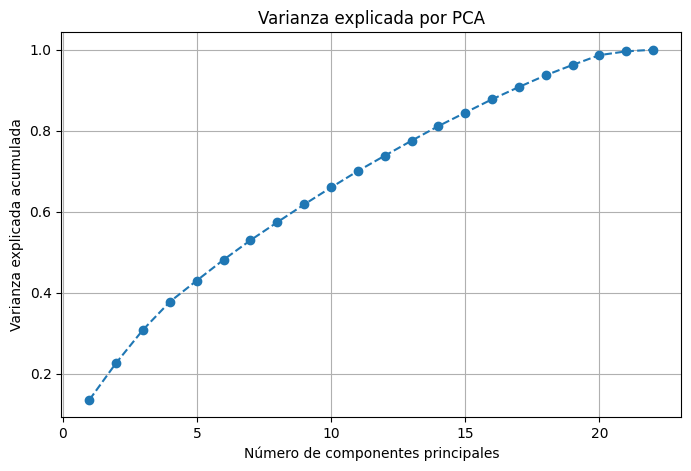

Número óptimo de componentes para explicar el 80% de la varianza: 14


In [99]:
# Estandarización de los datos
scaler = StandardScaler()
data_scaled = scaler.fit_transform(df_numeric)

# Aplicar PCA
pca = PCA()
pca_result = pca.fit_transform(data_scaled)

# Varianza explicada acumulada
explained_variance = pca.explained_variance_ratio_.cumsum()

# Graficar la varianza explicada
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o', linestyle='--')
plt.xlabel('Número de componentes principales')
plt.ylabel('Varianza explicada acumulada')
plt.title('Varianza explicada por PCA')
plt.grid()
plt.show()

# Elegir un número de componentes (ejemplo: 95% de varianza explicada)
num_components = next(i for i, v in enumerate(explained_variance) if v >= 0.80) + 1
print(f'Número óptimo de componentes para explicar el 80% de la varianza: {num_components}')

# Reducir la dimensionalidad
pca_optimal = PCA(n_components=num_components)
data_reduced = pca_optimal.fit_transform(data_scaled)
data_reduced = pd.DataFrame(data_reduced, columns=[f'PC{i}' for i in range(1, num_components + 1)])

In [100]:
data_reduced.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14
0,-1.303120,3.100051,-1.905432,-0.588453,-0.477634,-1.263601,1.208135,0.608772,0.177600,-1.247742,-0.895663,-1.282668,-1.243707,0.137281
1,0.430366,0.129396,2.153589,0.321545,-1.345813,0.985954,-1.061845,-2.870387,0.236929,-0.274228,0.920323,-0.307266,0.367306,0.727948
2,-0.382219,-1.253837,-0.123221,-0.034480,-0.221534,-0.329441,-0.529640,-0.281744,-0.061857,0.658373,-0.291355,0.360485,0.627505,-0.062289
3,-1.401687,-1.516231,-0.167051,-0.540551,0.231418,-0.523062,-0.597440,-1.043009,0.635981,-0.017339,0.158093,-0.888342,0.289797,-1.052352
4,-0.057874,0.022766,-0.812666,0.761205,-0.307166,0.940843,0.604887,1.212452,-0.436952,1.223270,-0.732690,-0.413510,0.487172,0.230605


# Assessing the Consistency between Existing Labels and Data Clusters

- To assess whether existing labels adequately describe data in terms of clusters, it is necessary to analyze their correspondence with the actual clusters present in the data. This involves checking whether the assigned labels accurately represent the patterns and characteristics inherent to the identified clusters.

In [101]:
df_categorical=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_categorical_features.csv',index_col=0)
for col in df_categorical.columns:
    print(f'{col}, unique values: {df_categorical[col].nunique()}')



sex, unique values: 2
dzgroup, unique values: 8
dzclass, unique values: 4
income, unique values: 5
race, unique values: 5
ca, unique values: 3
sfdm2, unique values: 6
death, unique values: 2
hospdead, unique values: 2
diabetes, unique values: 2
dementia, unique values: 2


### Number of clusters to analyze 2,3,4,5,6,8

````
import random
random.seed(10)

labels = [df_categorical[col] for col in df_categorical.columns]
k_values = [2, 3, 4, 5, 6, 7, 8]

# Definir una función para crear los modelos con k clusters
def models(k):
    algorithms = {
        'KMeans': KMeans(n_clusters=k),
        'Birch': Birch(n_clusters=k),
        'GaussianMixture': GaussianMixture(n_components=k)
        # No usamos el DSBCAN dado que no requiere un número de clusters
    }
    return algorithms

#Función para evaluar el rendimiento con métricas adicionales
def evaluate_clustering(algorithm, X, y):
    algorithm.fit(X)
    y_pred = algorithm.predict(X)
    
    # Métricas de rendimiento
    silhouette = silhouette_score(X, y_pred)
    homogeneity = homogeneity_score(y, y_pred)  # no presentan problemas de reasignación 
    completeness = completeness_score(y, y_pred) # no presentan problemas de reasignación
    v_score = v_measure_score(y, y_pred)    # no presentan problemas de reasignación
    calinski_harabasz = calinski_harabasz_score(X, y_pred)
    davies_bouldin = davies_bouldin_score(X, y_pred)
    
    return {
        'Silhouette Score': silhouette,
        'Homogeneity Score': homogeneity,
        'Completeness Score': completeness,
        'V-Score': v_score,
        'Calinski-Harabasz Index': calinski_harabasz,
        'Davies-Bouldin Index': davies_bouldin,
    }

# Evaluar los algoritmos para diferentes valores de k y para cada conjunto de etiquetas y
results_df = pd.DataFrame()

# Iterar sobre los conjuntos de etiquetas
for col_name, y in zip(df_categorical.columns, labels):  # Usamos el nombre de la columna directamente
    # Iterar sobre los valores de k
    print(f'Label: {col_name}')
    for k in k_values:
        algorithms = models(k)  
        # Evaluar cada algoritmo para el conjunto de etiquetas y
        for name, algo in algorithms.items():
            metrics = evaluate_clustering(algo, data_reduced, y)
            # Crear un DataFrame para cada modelo y conjunto de resultados
            metrics['Model'] = name
            metrics['Label'] = col_name
            metrics['k'] = k
            # Convertir el diccionario de métricas en un DataFrame y agregarlo a los resultados
            result_row = pd.DataFrame([metrics])
            results_df = pd.concat([results_df, result_row], ignore_index=True)

# Agrupar los resultados por modelo, etiqueta y k
grouped_results = results_df.groupby(['Model', 'Label', 'k']).agg({
    'Silhouette Score': 'mean',
    'Homogeneity Score': 'mean',
    'Completeness Score': 'mean',
    'V-Score': 'mean',
    'Calinski-Harabasz Index': 'mean',
    'Davies-Bouldin Index': 'mean'
})

# Mostrar los resultados agrupados
grouped_results.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Clustering Task3/Numerical_DF_Clustering_Analysis_NoDBSCAN.csv')

In [102]:
grouped_results=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Clustering Task3/Numerical_DF_Clustering_Analysis_NoDBSCAN.csv',index_col=[0,1,2])
grouped_results.head()

Silhouette Score  Homogeneity Score  Completeness Score  \
Model Label k                                                            
Birch ca    2          0.322074           0.005335            0.026742   
            3          0.127512           0.005738            0.010067   
            4          0.136605           0.006394            0.006895   
            5          0.078793           0.021123            0.013910   
            6          0.085623           0.021313            0.013501   

                V-Score  Calinski-Harabasz Index  Davies-Bouldin Index  
Model Label k                                                           
Birch ca    2  0.008895               640.145298              1.563623  
            3  0.007310               617.989300              1.937114  
            4  0.006635               604.940821              2.244032  
            5  0.016774               589.775479              2.683604  
            6  0.016531               548.511877              2.455708

## Labels for k=2

### SEX

In [103]:
df_sex=grouped_results.xs('sex', level='Label')
df_sex

Silhouette Score  Homogeneity Score  Completeness Score  \
Model           k                                                            
Birch           2          0.322074           0.000018            0.000072   
                3          0.127512           0.002312            0.003194   
                4          0.136605           0.002326            0.001975   
                5          0.078793           0.002624            0.001361   
                6          0.085623           0.002641            0.001318   
                7          0.087524           0.002651            0.001206   
                8          0.086779           0.002653            0.001191   
GaussianMixture 2          0.156439           0.000004            0.000004   
                3         -0.015522           0.000040            0.000027   
                4         -0.011188           0.000291            0.000146   
                5         -0.004115           0.001223            0.000555   
                6         -0.029578           0.002085            0.000869   
                7         -0.028778           0.003062            0.001168   
                8         -0.026755           0.003096            0.001064   
KMeans          2          0.170377           0.000041            0.000045   
                3          0.123343           0.000043            0.000032   
                4          0.105928           0.000085            0.000051   
                5          0.109550           0.002968            0.001447   
                6          0.113486           0.003298            0.001523   
                7          0.104010           0.003964            0.001614   
                8          0.058225           0.004670            0.001606   

                    V-Score  Calinski-Harabasz Index  Davies-Bouldin Index  
Model           k                                                           
Birch           2  0.000029               640.145298              1.563623  
                3  0.002683               617.989300              1.937114  
                4  0.002136               604.940821              2.244032  
                5  0.001792               589.775479              2.683604  
                6  0.001758               548.511877              2.455708  
                7  0.001658               502.720251              2.426202  
                8  0.001644               465.966552              2.221240  
GaussianMixture 2  0.000004               668.684499              3.448592  
                3  0.000033               461.825578              4.172250  
                4  0.000194               435.510051              3.912174  
                5  0.000763               468.717151              3.110335  
                6  0.001227               410.413248              4.100893  
                7  0.001691               357.806806              4.253809  
                8  0.001583               323.539194              4.909064  
KMeans          2  0.000043              1017.361266              2.713398  
                3  0.000037               832.327718              2.759040  
                4  0.000064               780.429515              2.449745  
                5  0.001946               801.928854              2.231500  
                6  0.002084               729.353291              2.103164  
                7  0.002294               665.608571              2.233918  
                8  0.002390               588.778559              2.452792

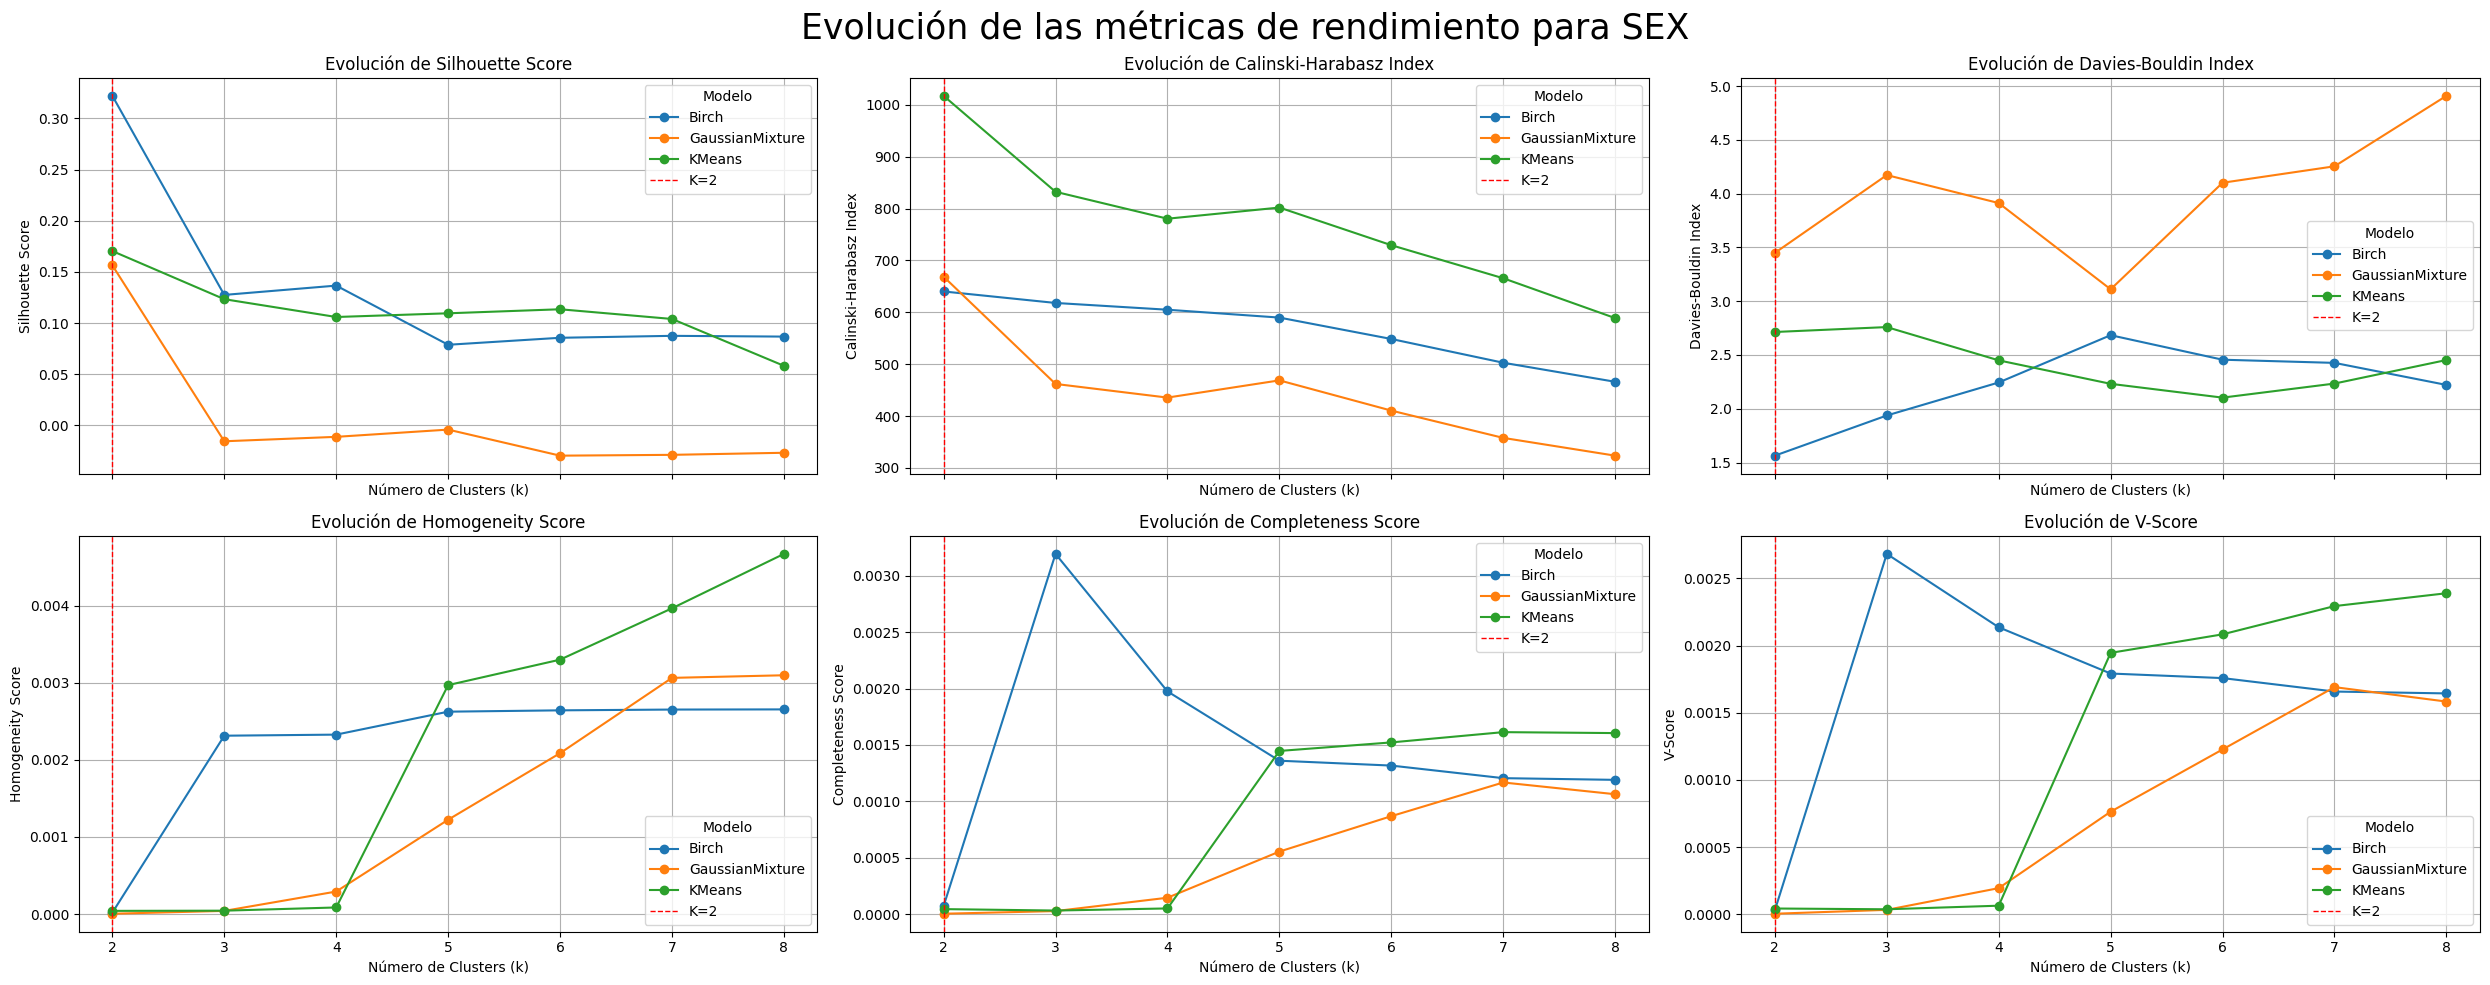

In [104]:
metrics = ["Silhouette Score",'Calinski-Harabasz Index','Davies-Bouldin Index', "Homogeneity Score", "Completeness Score", "V-Score"]
# Crear un subplot para cada métrica
fig, axes = plt.subplots(2, 3, figsize=(25, 10), sharex=True)
fig.suptitle('Evolución de las métricas de rendimiento para SEX', fontsize=25)
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]
    for model in df_sex.index.get_level_values("Model").unique():
        # Filtrar datos del modelo actual
        subset = df_sex.loc[model]
        ax.plot(subset.index, subset[metric], marker="o", label=model)
    
    ax.axvline(x=2, color="red", linestyle="--", linewidth=1, label="K=2")
    ax.set_title(f"Evolución de {metric}")
    ax.set_xlabel("Número de Clusters (k)")
    ax.set_ylabel(metric)
    ax.legend(title="Modelo")
    ax.grid(True)


plt.tight_layout()
plt.show()


When analyzing the graphs and considering that the original label "SEX" consists of two clusters: `female` and `male`, it is crucial to focus on the performance of the models specifically at \( k=2 \), as this aligns with the expected natural separation in the data. Below is a detailed summary of the findings:

1. **Silhouette Score**: At \( k=2 \), the **Birch** model demonstrates the best performance with a score close to 0.3, indicating a moderate separation between the clusters. In contrast, both **Gaussian Mixture** and **KMeans** yield significantly lower scores, highlighting a higher degree of overlap or confusion between clusters.

2. **Calinski-Harabasz Index**: This index, which assesses the compactness and separation of clusters, peaks at \( k=2 \) for all three models. Among them, **Birch** achieves the highest value, reinforcing that \( k=2 \) aligns well with the inherent structure of the data.

3. **Davies-Bouldin Index**: This metric evaluates the separation and compactness of clusters, where lower values are better. At \( k=2 \), **Birch** again performs the best, showcasing the most clearly defined clusters compared to **Gaussian Mixture** and **KMeans**.

4. **Homogeneity and Completeness Scores**: These metrics reveal the extent to which clusters reflect the true labels (`female` and `male`). At \( k=2 \), all models exhibit low scores, indicating that none of the models perfectly capture the original grouping. However, **Birch** achieves slightly better results than the other models.

5. **V-Score**: Similar to homogeneity and completeness, the **V-Score** at \( k=2 \) is also low across all models, further underscoring the limitations in accurately representing the original labels.

### Conclusion
While **Birch** emerges as the most promising model at \( k=2 \) based on metrics like Silhouette Score, Calinski-Harabasz Index, and Davies-Bouldin Index, the low values for homogeneity, completeness, and V-Score suggest that the clustering does not fully capture the underlying structure of the "SEX" label. This indicates that the features used for clustering may not adequately represent the "female" and "male" categories. 

---

### DEATH

In [105]:
df_death=grouped_results.xs('death', level='Label')
df_death

Silhouette Score  Homogeneity Score  Completeness Score  \
Model           k                                                            
Birch           2          0.322074           0.000491            0.001769   
                3          0.127512           0.004748            0.005988   
                4          0.136605           0.004755            0.003685   
                5          0.078793           0.004755            0.002251   
                6          0.085623           0.005626            0.002562   
                7          0.087524           0.005962            0.002476   
                8          0.086779           0.005965            0.002444   
GaussianMixture 2          0.156198           0.000728            0.000714   
                3         -0.015545           0.003796            0.002354   
                4         -0.015218           0.006463            0.003231   
                5         -0.003922           0.010555            0.004379   
                6         -0.032547           0.010633            0.004053   
                7         -0.035394           0.011654            0.004069   
                8         -0.061839           0.018253            0.005813   
KMeans          2          0.169600           0.000140            0.000140   
                3          0.135258           0.000699            0.000479   
                4          0.135993           0.009375            0.005043   
                5          0.109634           0.009814            0.004365   
                6          0.103231           0.007935            0.003102   
                7          0.062805           0.009774            0.003315   
                8          0.053691           0.011572            0.003588   

                    V-Score  Calinski-Harabasz Index  Davies-Bouldin Index  
Model           k                                                           
Birch           2  0.000769               640.145298              1.563623  
                3  0.005296               617.989300              1.937114  
                4  0.004152               604.940821              2.244032  
                5  0.003055               589.775479              2.683604  
                6  0.003521               548.511877              2.455708  
                7  0.003499               502.720251              2.426202  
                8  0.003468               465.966552              2.221240  
GaussianMixture 2  0.000721               668.467437              3.449437  
                3  0.002906               461.920153              4.169825  
                4  0.004308               447.509193              3.924034  
                5  0.006190               470.481704              3.116148  
                6  0.005869               410.250753              4.048801  
                7  0.006032               354.587792              4.102758  
                8  0.008818               301.884634              4.330091  
KMeans          2  0.000140              1017.329705              2.718184  
                3  0.000568               832.483873              2.759401  
                4  0.006558               830.842969              2.166380  
                5  0.006042               801.913723              2.230696  
                6  0.004460               708.772922              2.359487  
                7  0.004951               649.832102              2.424900  
                8  0.005478               591.360948              2.450677

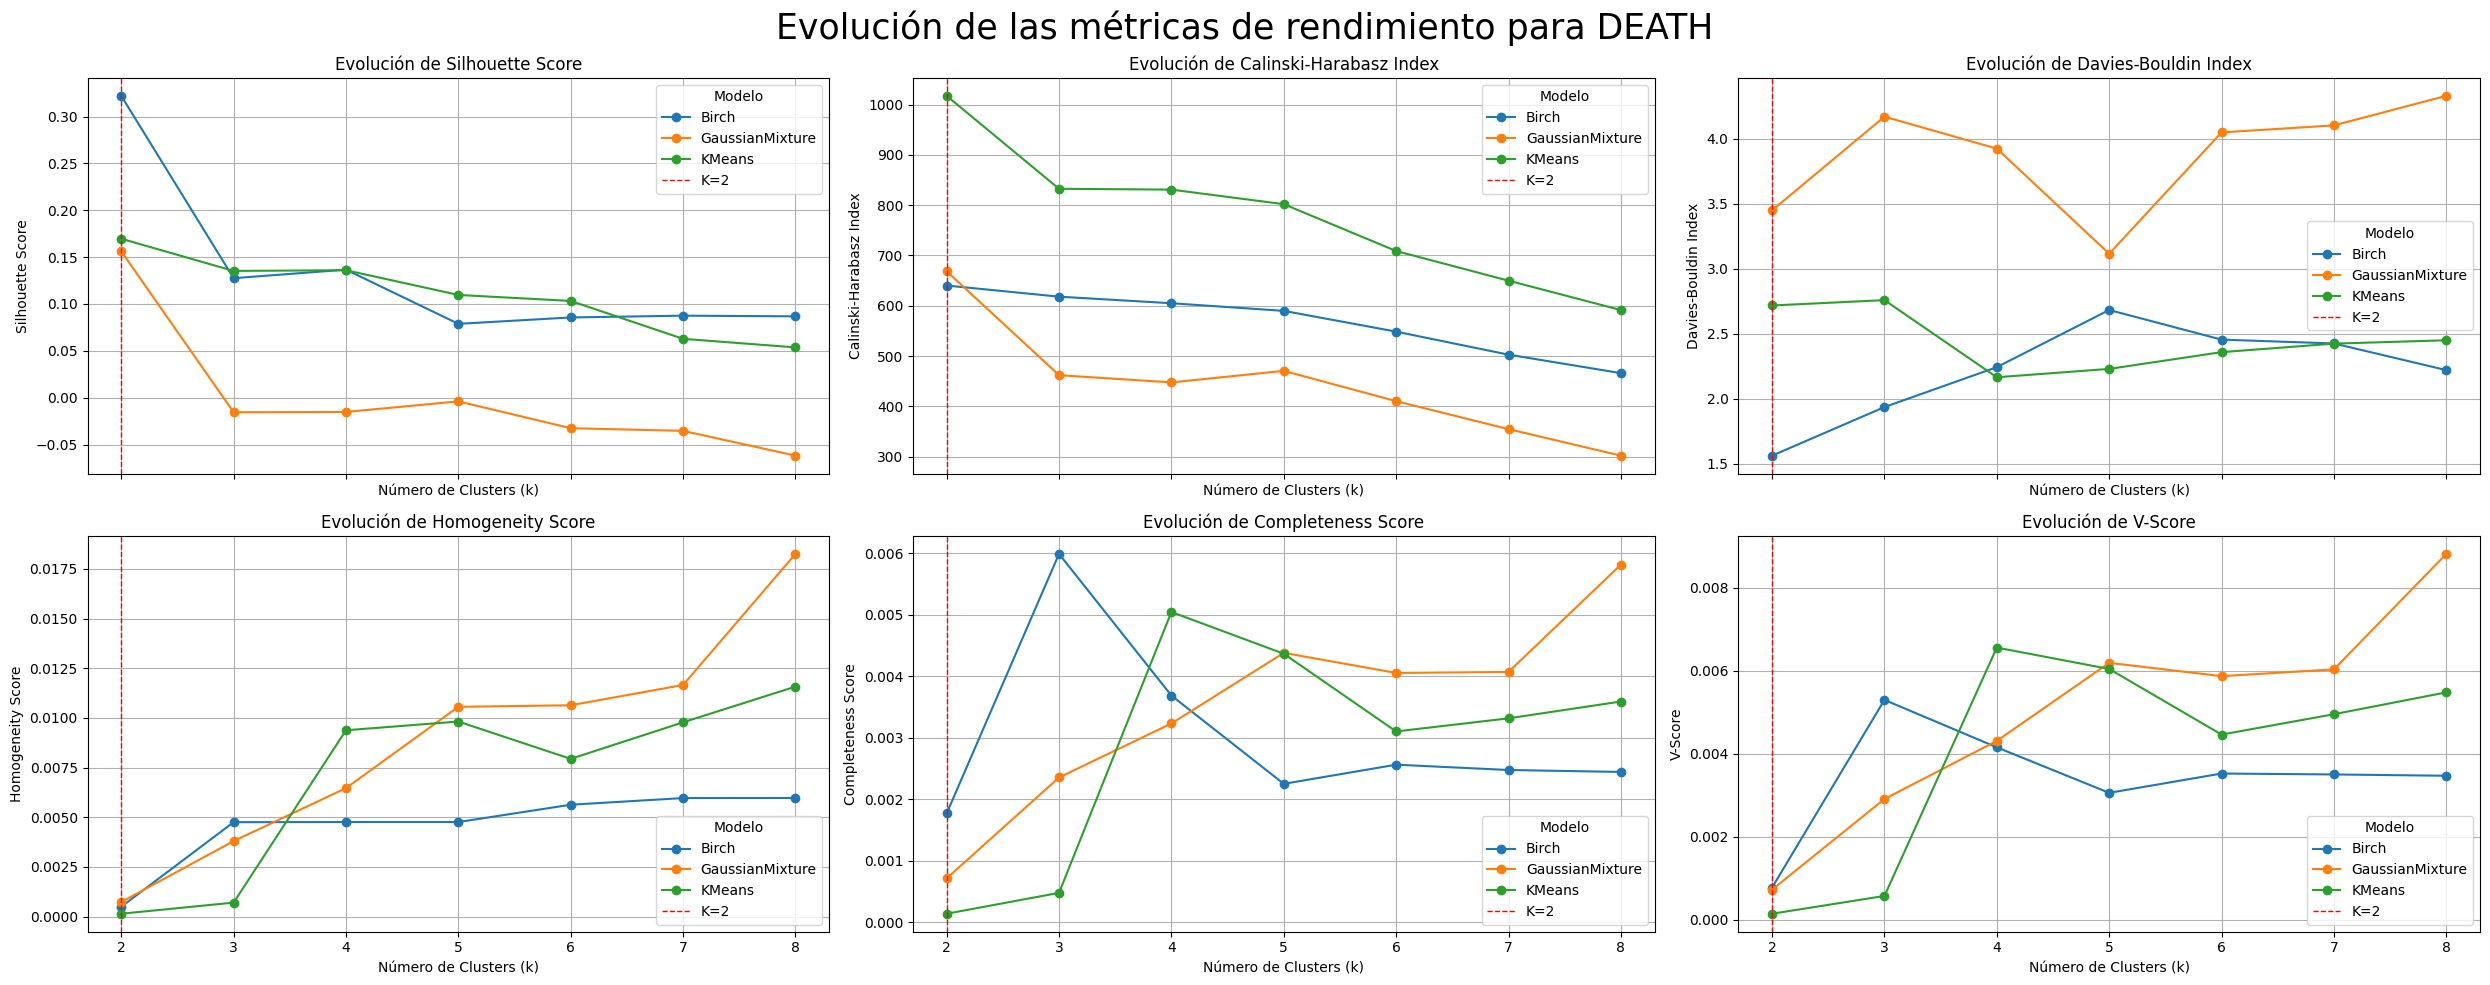

In [106]:
metrics = ["Silhouette Score",'Calinski-Harabasz Index','Davies-Bouldin Index', "Homogeneity Score", "Completeness Score", "V-Score"]
# Crear un subplot para cada métrica
fig, axes = plt.subplots(2, 3, figsize=(25, 10), sharex=True)
fig.suptitle('Evolución de las métricas de rendimiento para DEATH', fontsize=25)
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]
    for model in df_death.index.get_level_values("Model").unique():
        # Filtrar datos del modelo actual
        subset = df_death.loc[model]
        ax.plot(subset.index, subset[metric], marker="o", label=model)
    
    ax.axvline(x=2, color="red", linestyle="--", linewidth=1, label="K=2")
    ax.set_title(f"Evolución de {metric}")
    ax.set_xlabel("Número de Clusters (k)")
    ax.set_ylabel(metric)
    ax.legend(title="Modelo")
    ax.grid(True)


plt.tight_layout()
plt.show()

In this analysis, we evaluate the graphs related to the "DEATH" category, where the main classes are `alive` and `dead`. The focus is on \( k=2 \), as it reflects the expected binary structure of the data. Below is a detailed breakdown of the findings:

1. **Silhouette Score**: The **Birch** model achieves the highest score at \( k=2 \), approximately 0.3, indicating moderate separation between the clusters. However, **KMeans** and **Gaussian Mixture** exhibit much lower values, reflecting less clarity in the separation of groups.

2. **Calinski-Harabasz Index**: At \( k=2 \), all models reach their highest values for this metric, with **KMeans** achieving the best result. This suggests that \( k=2 \) is consistent with the inherent structure of the data, as evaluated by compactness and separation.

3. **Davies-Bouldin Index**: Lower values in this metric indicate better-defined clusters. At \( k=2 \), **Birch** and **KMeans** perform well with relatively low values, showing more distinct and compact clusters. **Gaussian Mixture**, however, has higher values, indicating greater overlap and less distinction between clusters.

4. **Homogeneity, Completeness, and V-Score**: These metrics, which assess how well the clusters reflect the true classes (`alive` and `dead`), are extremely low across all models at \( k=2 \). This indicates that none of the clustering methods succeed in accurately capturing the underlying structure of the `alive` and `dead` classes. 

### Conclusion
While \( k=2 \) aligns with the expected binary structure of the data, the extremely low values for Homogeneity, Completeness, and V-Score reveal significant limitations in how well the clusters represent the true `alive` and `dead` classes. Despite **Birch** showing strong performance in clustering separation metrics such as Silhouette and Davies-Bouldin, these results indicate that the features or data used for clustering do not adequately capture the distinctions between `alive` and `dead`. 

---


## HOSPDEAD

In [107]:
df_hospdead=grouped_results.xs('hospdead', level='Label')
df_hospdead

Silhouette Score  Homogeneity Score  Completeness Score  \
Model           k                                                            
Birch           2          0.322074           0.014068            0.046295   
                3          0.127512           0.016601            0.019120   
                4          0.136605           0.019213            0.013601   
                5          0.078793           0.067185            0.029047   
                6          0.085623           0.072106            0.029989   
                7          0.087524           0.072569            0.027520   
                8          0.086779           0.072580            0.027160   
GaussianMixture 2          0.156389           0.044409            0.039774   
                3         -0.015633           0.063438            0.035909   
                4         -0.020963           0.073263            0.032847   
                5         -0.004090           0.074331            0.028119   
                6         -0.014130           0.100573            0.034356   
                7         -0.049180           0.097412            0.030601   
                8         -0.023132           0.103651            0.029791   
KMeans          2          0.170081           0.086271            0.079123   
                3          0.132166           0.090579            0.054089   
                4          0.120370           0.075725            0.035728   
                5          0.109835           0.072675            0.029566   
                6          0.061976           0.072093            0.024532   
                7          0.067184           0.078406            0.025626   
                8          0.067725           0.089503            0.026901   

                    V-Score  Calinski-Harabasz Index  Davies-Bouldin Index  
Model           k                                                           
Birch           2  0.021578               640.145298              1.563623  
                3  0.017772               617.989300              1.937114  
                4  0.015928               604.940821              2.244032  
                5  0.040559               589.775479              2.683604  
                6  0.042360               548.511877              2.455708  
                7  0.039906               502.720251              2.426202  
                8  0.039528               465.966552              2.221240  
GaussianMixture 2  0.041964               668.670991              3.448732  
                3  0.045859               461.873439              4.172974  
                4  0.045358               394.176545              4.363939  
                5  0.040802               468.772668              3.109833  
                6  0.051217               431.545103              4.117661  
                7  0.046572               350.137804              3.550711  
                8  0.046280               324.454577              4.273404  
KMeans          2  0.082542              1017.339462              2.715280  
                3  0.067732               898.473369              2.347586  
                4  0.048550               831.662149              2.456800  
                5  0.042032               801.929987              2.229016  
                6  0.036607               714.421547              2.378890  
                7  0.038627               671.415151              2.243005  
                8  0.041368               624.886612              2.284273

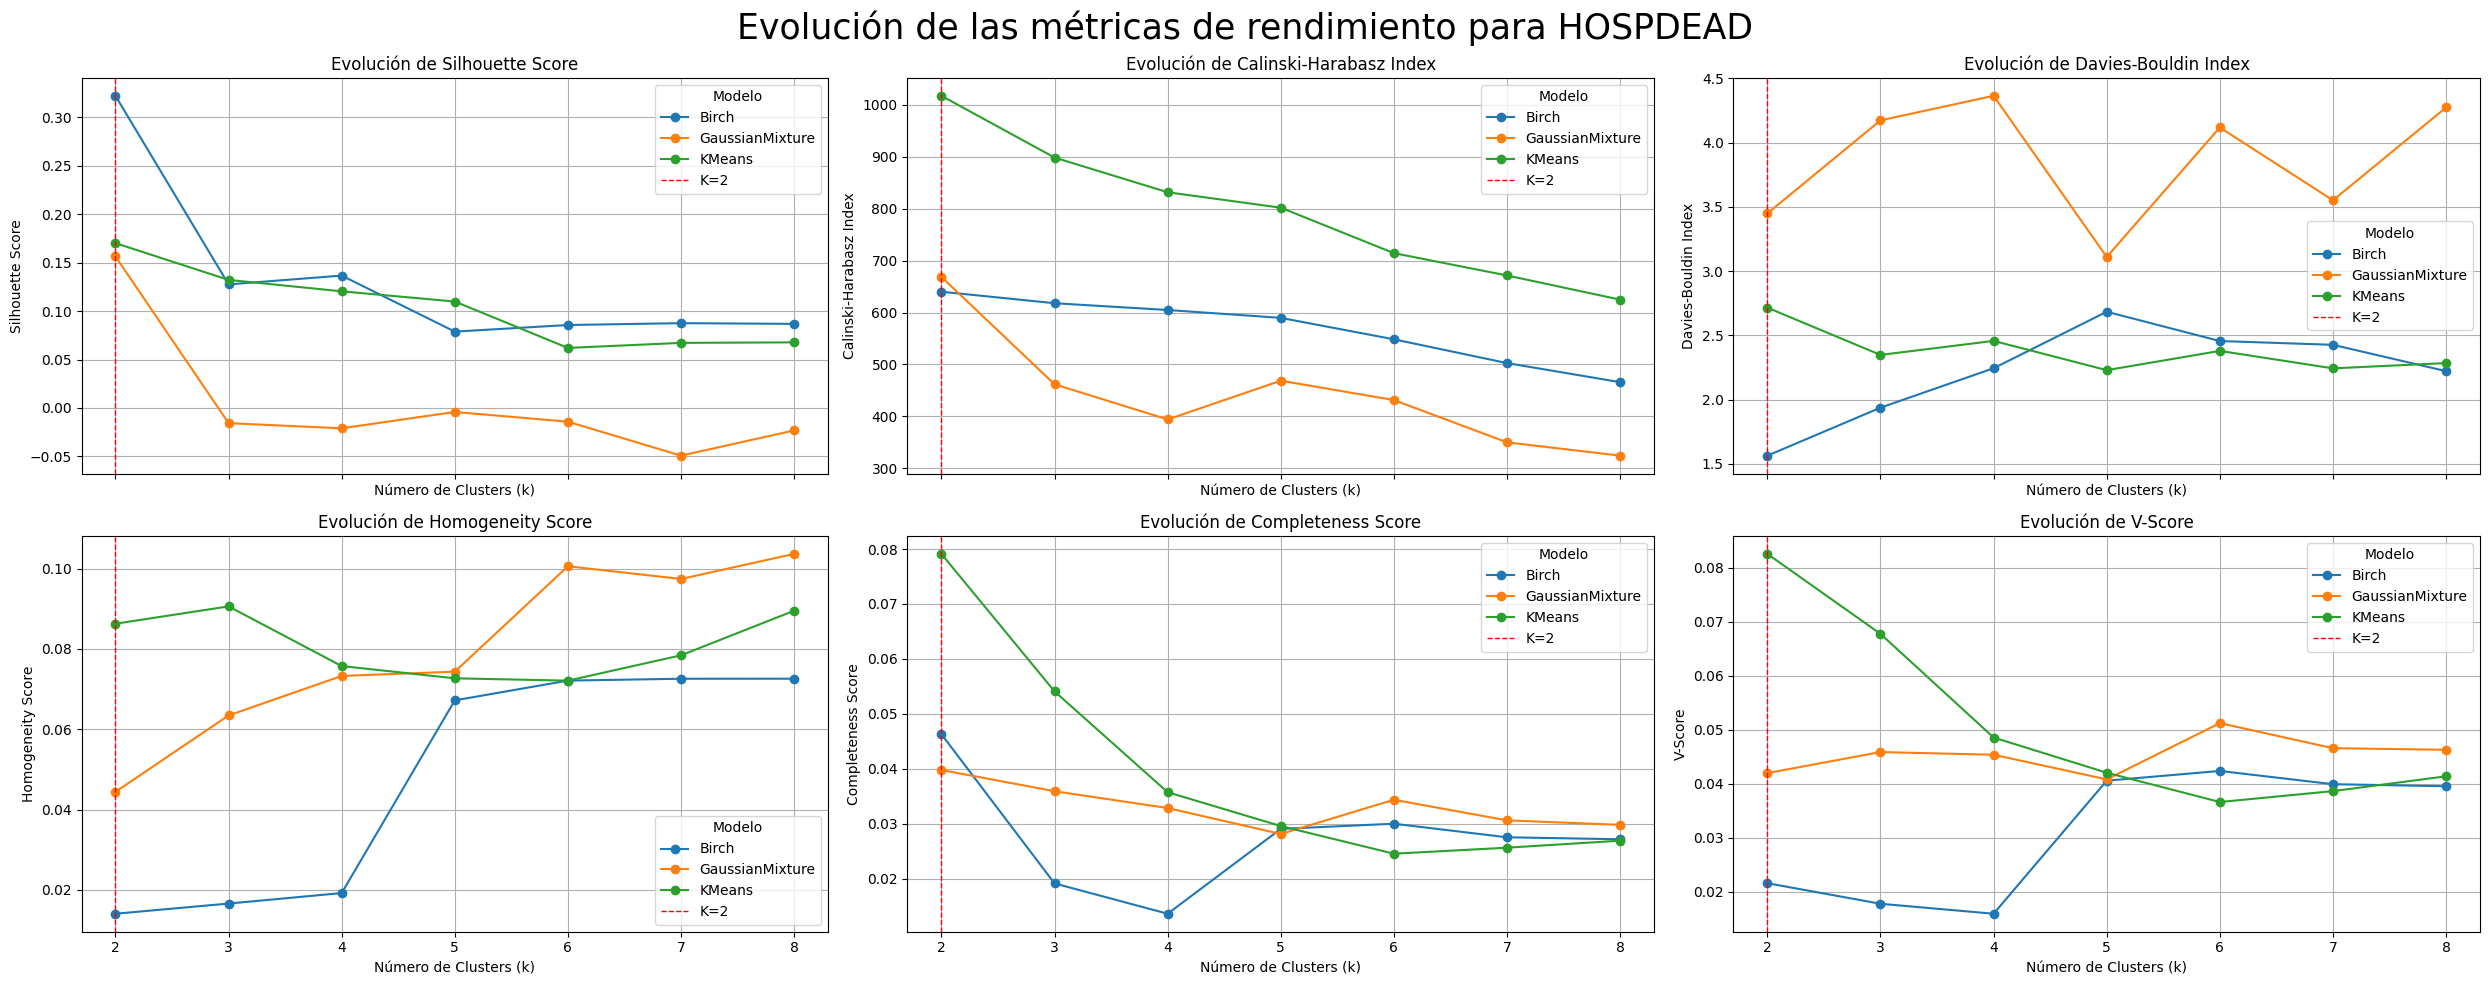

In [108]:
metrics = ["Silhouette Score",'Calinski-Harabasz Index','Davies-Bouldin Index', "Homogeneity Score", "Completeness Score", "V-Score"]
# Crear un subplot para cada métrica
fig, axes = plt.subplots(2, 3, figsize=(25, 10), sharex=True)
fig.suptitle('Evolución de las métricas de rendimiento para HOSPDEAD', fontsize=25)
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]
    for model in df_hospdead.index.get_level_values("Model").unique():
        # Filtrar datos del modelo actual
        subset = df_hospdead.loc[model]
        ax.plot(subset.index, subset[metric], marker="o", label=model)
    
    ax.axvline(x=2, color="red", linestyle="--", linewidth=1, label="K=2")
    ax.set_title(f"Evolución de {metric}")
    ax.set_xlabel("Número de Clusters (k)")
    ax.set_ylabel(metric)
    ax.legend(title="Modelo")
    ax.grid(True)


plt.tight_layout()
plt.show()


In this analysis, we evaluate the results of the models for the category "HOSPDEAD," where the primary classes are `alive` and `dead in hospital`. We focus on \( k=2 \), as this value directly reflects the expected structure of the data. Below are the key observations:

1. **Silhouette Score**: The **Birch** model achieves the best performance at \( k=2 \), with a score close to 0.3, indicating moderate separation between clusters. In contrast, **Gaussian Mixture** and **KMeans** present lower values, suggesting less distinct separation between groups.

2. **Calinski-Harabasz Index**: At \( k=2 \), all models reach their peak performance for this metric, with **KMeans** demonstrating the best result. This indicates that \( k=2 \) is well-suited to capture the natural structure of the data, although both **Birch** and **Gaussian Mixture** also achieve reasonable values.

3. **Davies-Bouldin Index**: In this metric, lower values correspond to better-defined clusters. At \( k=2 \), both **Birch** and **KMeans** excel with relatively low values, highlighting their ability to form well-defined and compact clusters. **Gaussian Mixture**, on the other hand, has higher values, reflecting less distinct grouping.

4. **Homogeneity, Completeness, and V-Score**: These metrics, which measure how well the clusters reflect the true classes (`alive` and `dead in hospital`), exhibit low values across all models at \( k=2 \). However, **Gaussian Mixture** and **KMeans** slightly outperform **Birch**, indicating that these models offer a better—though still limited—representation of the true class structure. While these scores are low in absolute terms, they represent the best results obtained so far, suggesting incremental improvement over previous attempts.

### Conclusion
While \( k=2 \) remains the logical choice for separating the `alive` and `dead in hospital` classes, the overall low values for Homogeneity, Completeness, and V-Score indicate that the clustering models are not yet able to fully capture the true structure of the data. Nevertheless, **Gaussian Mixture** and **KMeans** provide the best performance for these metrics to date, suggesting that progress has been made. **Birch**, on the other hand, continues to excel in separation-focused metrics like Silhouette and Davies-Bouldin, which highlights its ability to form distinct clusters.

--- 

### DIABETES

In [109]:
df_diabetes=grouped_results.xs('diabetes', level='Label')
df_diabetes

Silhouette Score  Homogeneity Score  Completeness Score  \
Model           k                                                            
Birch           2          0.322074           0.000727            0.002074   
                3          0.127512           0.002255            0.002250   
                4          0.136605           0.002339            0.001435   
                5          0.078793           0.002567            0.000962   
                6          0.085623           0.003986            0.001436   
                7          0.087524           0.004925            0.001618   
                8          0.086779           0.004970            0.001611   
GaussianMixture 2          0.156256           0.000018            0.000014   
                3         -0.015463           0.000909            0.000446   
                4         -0.020961           0.001386            0.000538   
                5         -0.004123           0.015559            0.005100   
                6         -0.002940           0.014445            0.004430   
                7         -0.003657           0.007842            0.002159   
                8         -0.041359           0.009769            0.002547   
KMeans          2          0.170751           0.001328            0.001061   
                3          0.133086           0.008012            0.004147   
                4          0.137748           0.008066            0.003440   
                5          0.109481           0.008326            0.002930   
                6          0.061768           0.034343            0.010130   
                7          0.063005           0.042824            0.011496   
                8          0.062198           0.045513            0.011638   

                    V-Score  Calinski-Harabasz Index  Davies-Bouldin Index  
Model           k                                                           
Birch           2  0.001077               640.145298              1.563623  
                3  0.002252               617.989300              1.937114  
                4  0.001779               604.940821              2.244032  
                5  0.001399               589.775479              2.683604  
                6  0.002112               548.511877              2.455708  
                7  0.002436               502.720251              2.426202  
                8  0.002434               465.966552              2.221240  
GaussianMixture 2  0.000016               668.277805              3.449912  
                3  0.000599               461.747884              4.174995  
                4  0.000775               394.182484              4.363099  
                5  0.007682               468.498762              3.109073  
                6  0.006780               429.480682              3.167581  
                7  0.003386               377.573818              3.428628  
                8  0.004041               348.684828              3.526087  
KMeans          2  0.001180              1017.374446              2.707265  
                3  0.005465               898.469868              2.349374  
                4  0.004823               830.628276              2.145104  
                5  0.004335               801.920766              2.231532  
                6  0.015645               714.276428              2.384307  
                7  0.018126               649.835245              2.428479  
                8  0.018536               598.336054              2.411311

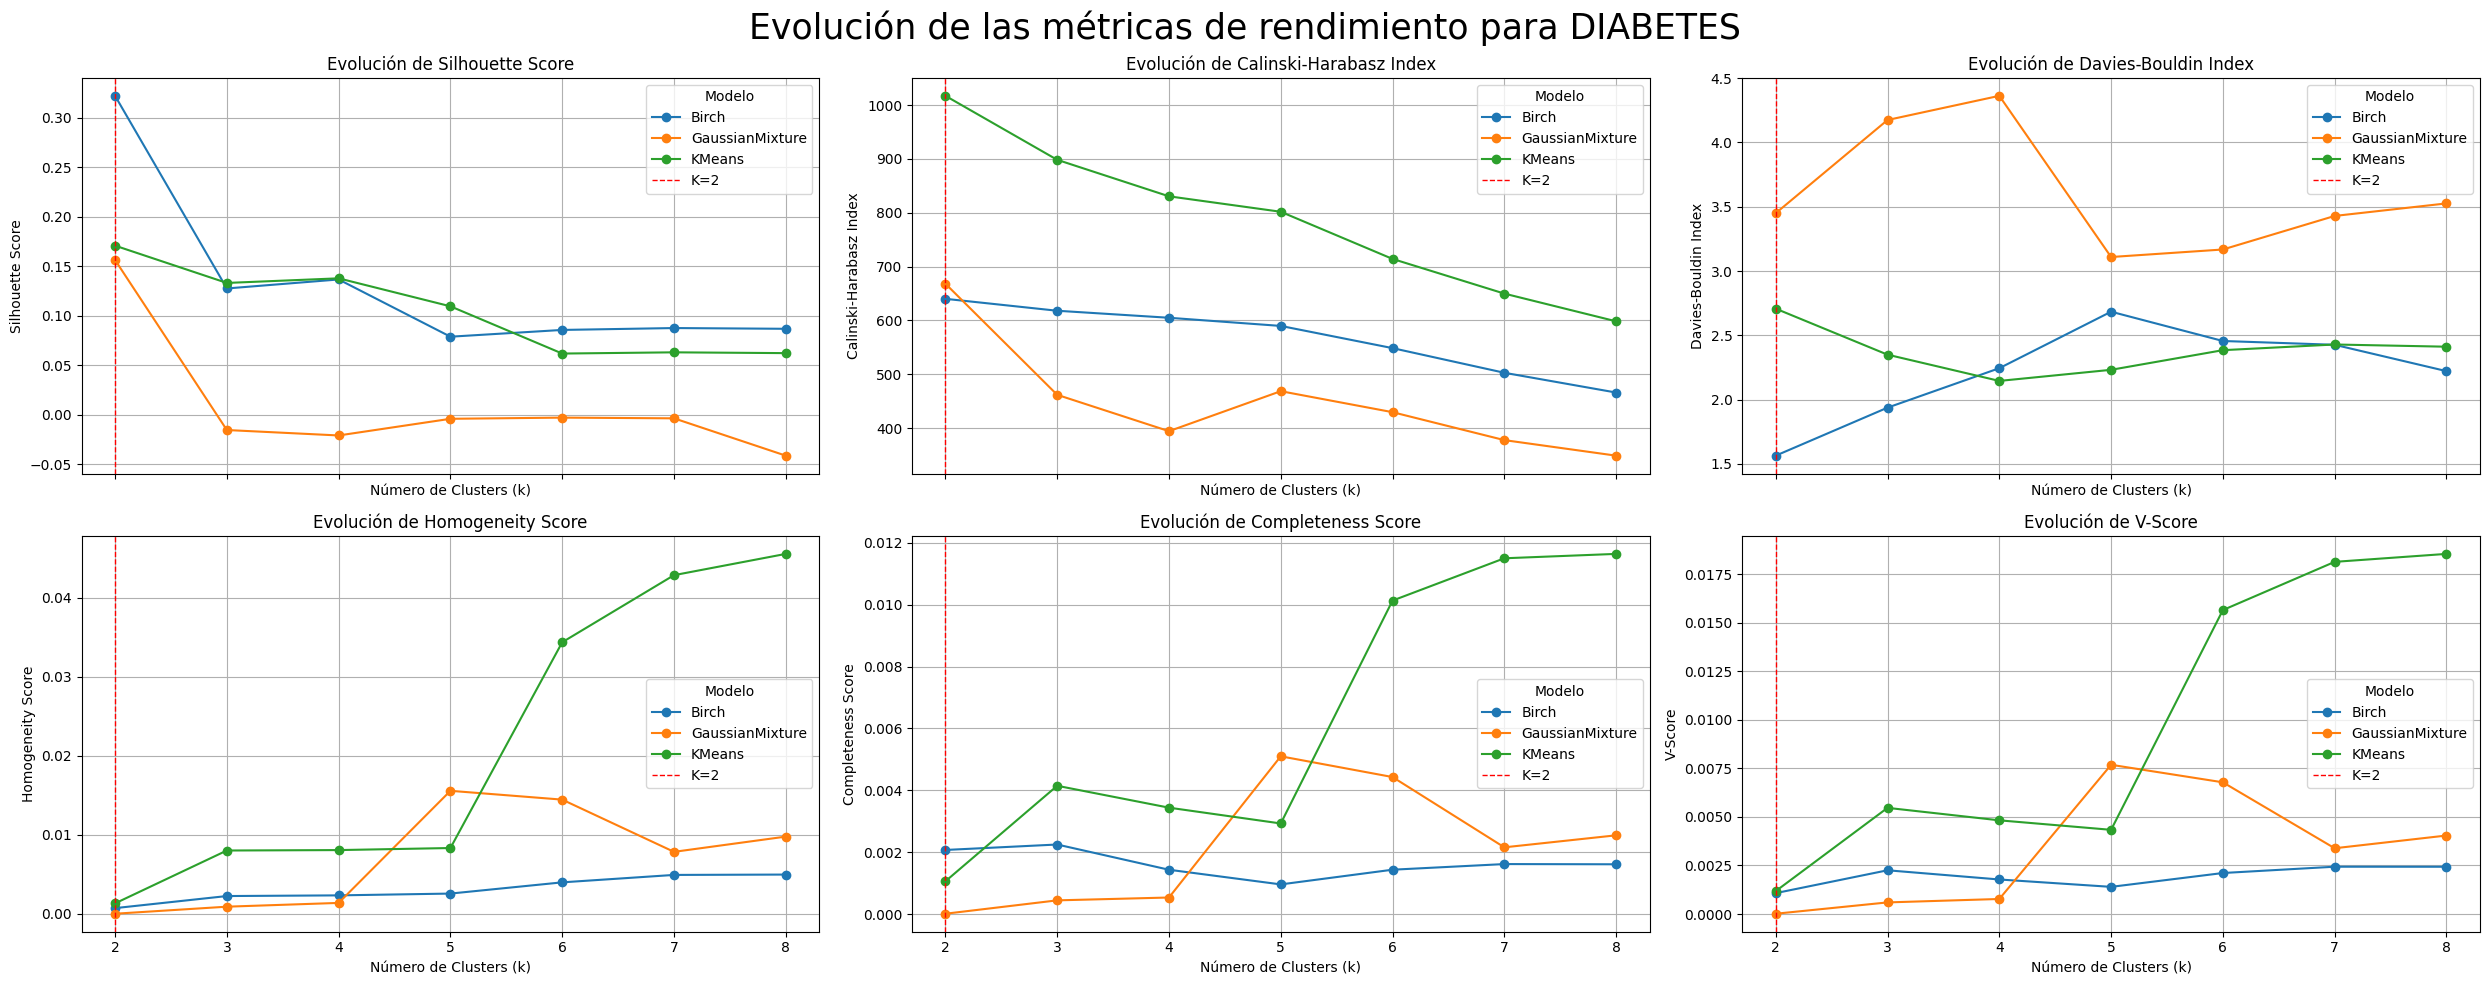

In [110]:
metrics = ["Silhouette Score",'Calinski-Harabasz Index','Davies-Bouldin Index', "Homogeneity Score", "Completeness Score", "V-Score"]
# Crear un subplot para cada métrica
fig, axes = plt.subplots(2, 3, figsize=(25, 10), sharex=True)
fig.suptitle('Evolución de las métricas de rendimiento para DIABETES', fontsize=25)
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]
    for model in df_diabetes.index.get_level_values("Model").unique():
        # Filtrar datos del modelo actual
        subset = df_diabetes.loc[model]
        ax.plot(subset.index, subset[metric], marker="o", label=model)
    
    ax.axvline(x=2, color="red", linestyle="--", linewidth=1, label="K=2")
    ax.set_title(f"Evolución de {metric}")
    ax.set_xlabel("Número de Clusters (k)")
    ax.set_ylabel(metric)
    ax.legend(title="Modelo")
    ax.grid(True)


plt.tight_layout()
plt.show()


In this analysis, we evaluate the results for the "DIABETES" category, where the main classes are `suffers from diabetes` and `does not suffer from diabetes`. We focus on \( k=2 \), as it represents the expected binary structure of the data. The analysis of the graphs has yielded the following key insights:

1. **Silhouette Score**: The **Birch** model achieves the highest score at \( k=2 \), with a value close to 0.3, indicating moderate separation between clusters. However, **Gaussian Mixture** and **KMeans** exhibit lower values, suggesting a lesser degree of separation and more overlap between clusters.

2. **Calinski-Harabasz Index**: At \( k=2 \), all models achieve their peak performance. **KMeans** stands out as the most effective at capturing the overall structure of the data, followed by **Birch**, while **Gaussian Mixture** underperforms in this metric.

3. **Davies-Bouldin Index**: For this metric, lower values correspond to better-defined clusters. Both **Birch** and **KMeans** achieve low values at \( k=2 \), indicating well-defined and compact clusters. In contrast, **Gaussian Mixture** exhibits significantly higher values, reflecting greater confusion and overlap among clusters.

4. **Homogeneity, Completeness, and V-Score**: These metrics, which assess how well the clusters represent the true classes (`suffers from diabetes` and `does not suffer from diabetes`), have very low values for all models at \( k=2 \). Among the models, **KMeans** performs slightly better, suggesting it captures some aspects of the class structure better than the others. However, the scores remain extremely low overall, indicating that none of the models can reliably reflect the actual class distribution. **Birch** and **Gaussian Mixture** perform worse in these metrics, further highlighting the limitations in their ability to accurately represent the `diabetes` classes.

### Conclusion
While \( k=2 \) aligns with the binary nature of the `diabetes` category, the very low values of Homogeneity, Completeness, and V-Score indicate that the clustering models struggle to accurately represent the true class structure. **KMeans** shows marginally better results in these metrics, while **Birch** excels in separation-based metrics like Silhouette and Davies-Bouldin. **Gaussian Mixture** underperforms across most metrics

---

### Dementia

In [111]:
df_dementia=grouped_results.xs('dementia', level='Label')
df_dementia

Silhouette Score  Homogeneity Score  Completeness Score  \
Model           k                                                            
Birch           2          0.322074           0.005396            0.004525   
                3          0.127512           0.043674            0.012817   
                4          0.136605           0.044692            0.008061   
                5          0.078793           0.046467            0.005119   
                6          0.085623           0.052357            0.005548   
                7          0.087524           0.055675            0.005380   
                8          0.086779           0.055979            0.005338   
GaussianMixture 2          0.156273           0.004030            0.000919   
                3          0.075119           0.006224            0.000976   
                4         -0.023650           0.021563            0.002442   
                5         -0.004120           0.085548            0.008238   
                6         -0.018677           0.052060            0.004488   
                7         -0.046007           0.045669            0.003668   
                8         -0.022999           0.044613            0.003270   
KMeans          2          0.112037           0.166828            0.044647   
                3          0.133143           0.164912            0.025114   
                4          0.106686           0.016391            0.002096   
                5          0.110173           0.124034            0.012866   
                6          0.061503           0.112953            0.009789   
                7          0.053762           0.109938            0.008553   
                8          0.084262           0.105427            0.008337   

                    V-Score  Calinski-Harabasz Index  Davies-Bouldin Index  
Model           k                                                           
Birch           2  0.004922               640.145298              1.563623  
                3  0.019818               617.989300              1.937114  
                4  0.013659               604.940821              2.244032  
                5  0.009222               589.775479              2.683604  
                6  0.010033               548.511877              2.455708  
                7  0.009811               502.720251              2.426202  
                8  0.009746               465.966552              2.221240  
GaussianMixture 2  0.001497               668.849752              3.448347  
                3  0.001687               550.602625              3.589141  
                4  0.004388               381.327431              4.464983  
                5  0.015028               468.708413              3.104518  
                6  0.008264               430.522876              4.291815  
                7  0.006790               357.325162              3.665258  
                8  0.006094               325.008135              4.243582  
KMeans          2  0.070442               742.680374              2.712348  
                3  0.043590               898.479056              2.348756  
                4  0.003717               780.426733              2.447235  
                5  0.023313               801.918606              2.227258  
                6  0.018016               714.361031              2.381236  
                7  0.015872               636.767733              2.440775  
                8  0.015452               581.947841              2.301799

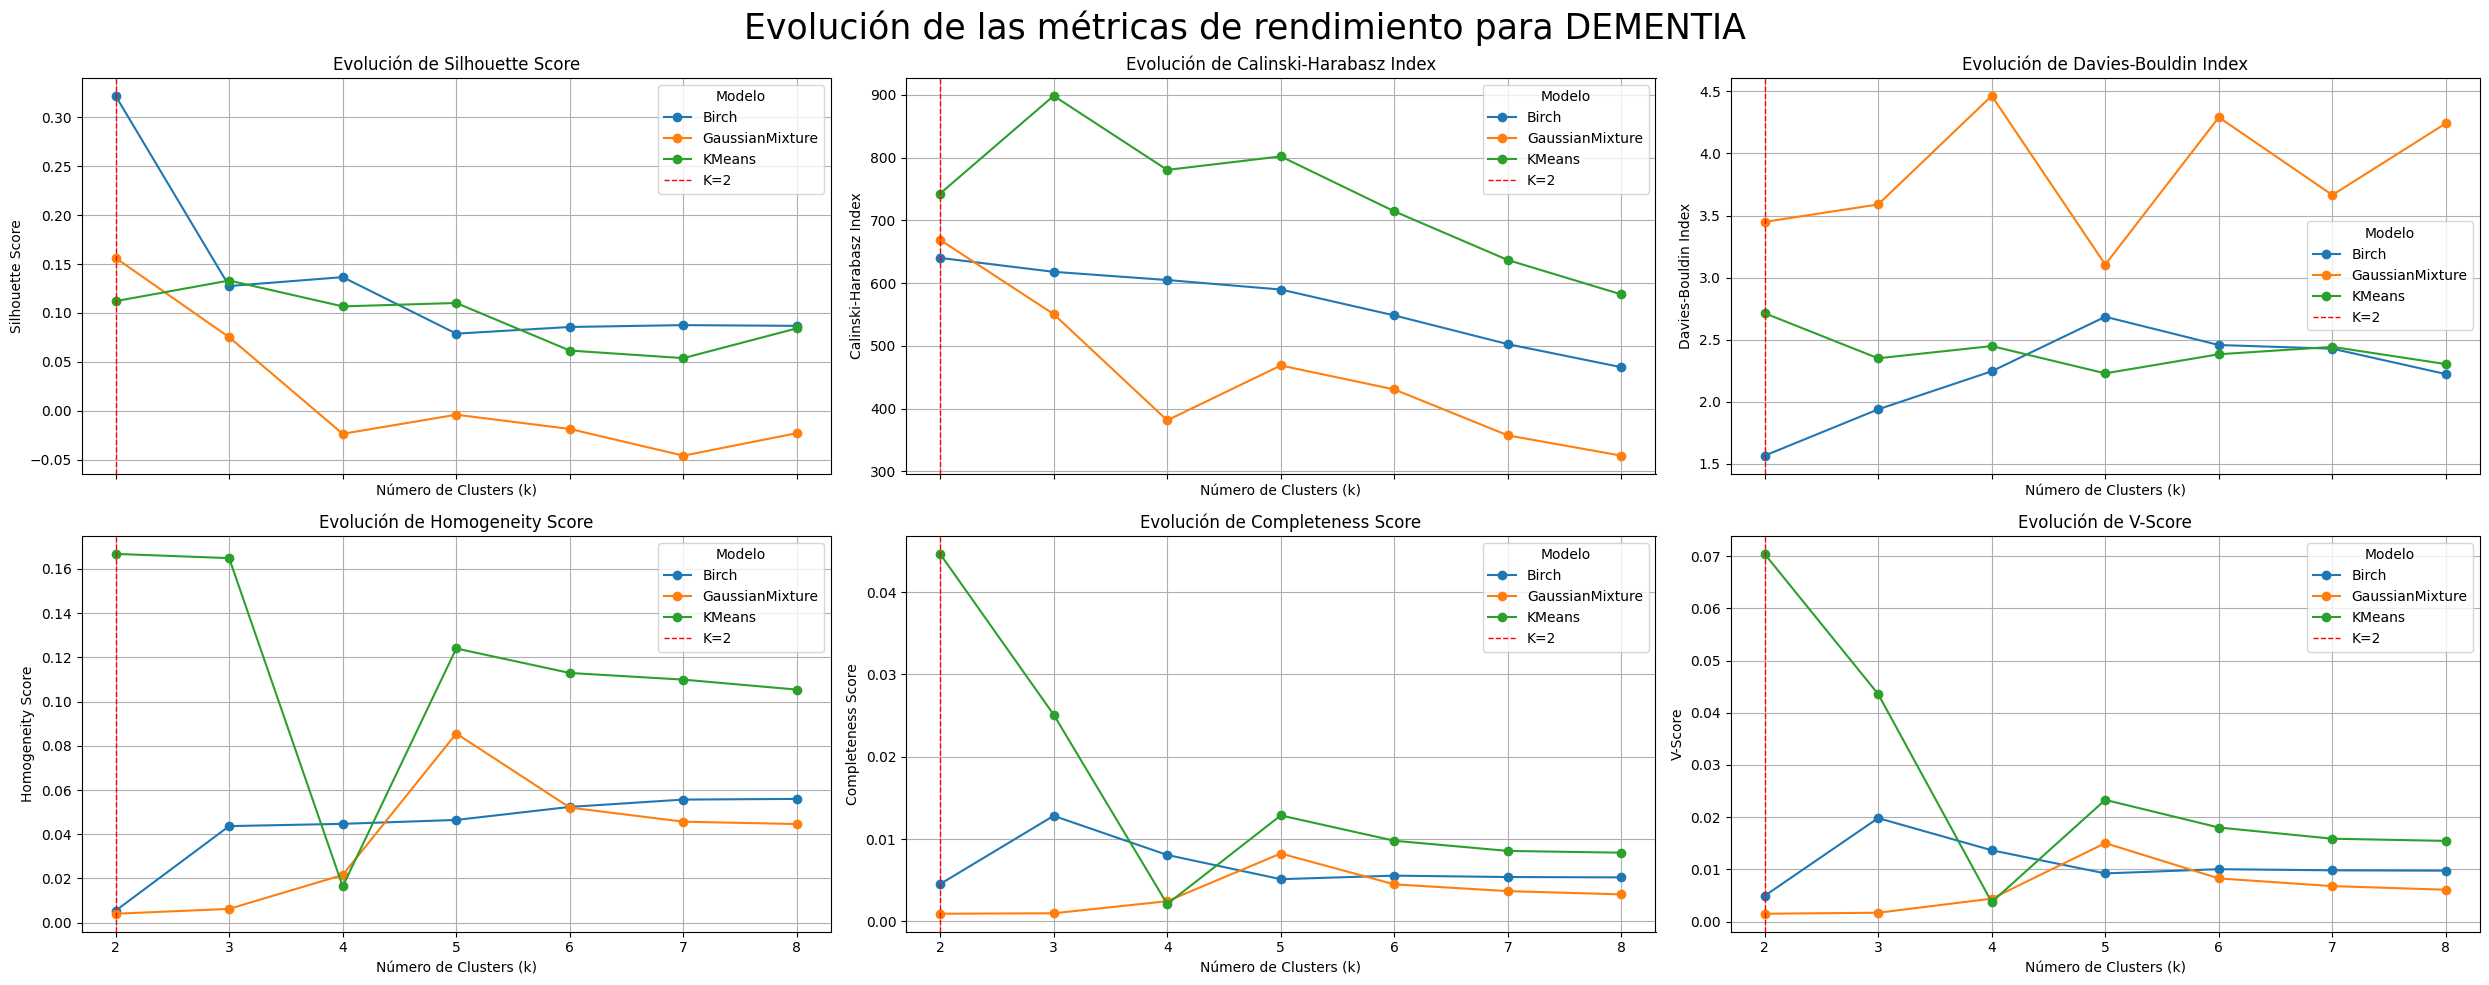

In [112]:
metrics = ["Silhouette Score",'Calinski-Harabasz Index','Davies-Bouldin Index', "Homogeneity Score", "Completeness Score", "V-Score"]
# Crear un subplot para cada métrica
fig, axes = plt.subplots(2, 3, figsize=(25, 10), sharex=True)
fig.suptitle('Evolución de las métricas de rendimiento para DEMENTIA', fontsize=25)
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]
    for model in df_dementia.index.get_level_values("Model").unique():
        # Filtrar datos del modelo actual
        subset = df_dementia.loc[model]
        ax.plot(subset.index, subset[metric], marker="o", label=model)
    
    ax.axvline(x=2, color="red", linestyle="--", linewidth=1, label="K=2")
    ax.set_title(f"Evolución de {metric}")
    ax.set_xlabel("Número de Clusters (k)")
    ax.set_ylabel(metric)
    ax.legend(title="Modelo")
    ax.grid(True)


plt.tight_layout()
plt.show()


In this analysis, we evaluate the results for the category "DEMENTIA," where the classes are `suffers from dementia` and `does not suffer from dementia`. We focus on \( k=2 \), as this value reflects the expected binary structure of the data. Below are the key findings:

1. **Silhouette Score**: The **Birch** model achieves the highest score at \( k=2 \), with a value close to 0.3, indicating moderate separation between clusters. In contrast, **Gaussian Mixture** and **KMeans** show lower values, suggesting less distinct separation of the clusters.

2. **Calinski-Harabasz Index**: At \( k=2 \), all models reach their peak performance for this metric. **KMeans** stands out as the most effective in capturing the overall structure of the data, while **Birch** provides competitive results. **Gaussian Mixture**, however, underperforms in this metric, indicating less clear group definitions.

3. **Davies-Bouldin Index**: For this metric, lower values signify better-defined clusters. Both **Birch** and **KMeans** perform well at \( k=2 \), reflecting well-separated clusters, whereas **Gaussian Mixture** shows higher values, indicating greater overlap between clusters.

4. **Homogeneity, Completeness, and V-Score**: These metrics, which assess how well the clusters match the true classes (`suffers from dementia` and `does not suffer from dementia`), exhibit very low values across all models at \( k=2 \). Among the models, **KMeans** achieves slightly better results, suggesting it captures some aspects of the class structure more effectively than the others. Nevertheless, these values remain extremely low, indicating that none of the models adequately reflect the true class distribution. **Birch** and **Gaussian Mixture** show even poorer performance in these metrics, further highlighting the limitations in representing the binary nature of dementia.

### Conclusion
While \( k=2 \) aligns with the expected binary classification for dementia, the very low values of Homogeneity, Completeness, and V-Score demonstrate significant limitations in how well the clusters represent the true class structure. **KMeans** provides marginally better results in these metrics, while **Birch** excels in separation-focused metrics like Silhouette and Davies-Bouldin. **Gaussian Mixture** performs the weakest overall, particularly in defining well-separated clusters.

---

## Labels for K=3

### Cancer

In [113]:
df_ca=grouped_results.xs('ca', level='Label')
df_ca

Silhouette Score  Homogeneity Score  Completeness Score  \
Model           k                                                            
Birch           2          0.322074           0.005335            0.026742   
                3          0.127512           0.005738            0.010067   
                4          0.136605           0.006394            0.006895   
                5          0.078793           0.021123            0.013910   
                6          0.085623           0.021313            0.013501   
                7          0.087524           0.021854            0.012624   
                8          0.086779           0.022593            0.012878   
GaussianMixture 2          0.156148           0.008143            0.011102   
                3         -0.015522           0.024487            0.021122   
                4         -0.023539           0.029451            0.019974   
                5         -0.004129           0.032267            0.018593   
                6         -0.004747           0.034419            0.018112   
                7         -0.017119           0.037081            0.017333   
                8         -0.030874           0.036467            0.015901   
KMeans          2          0.172650           0.029727            0.042451   
                3          0.131924           0.028728            0.026116   
                4          0.105948           0.020461            0.015571   
                5          0.109477           0.020685            0.012797   
                6          0.061991           0.029973            0.015570   
                7          0.062823           0.038988            0.018397   
                8          0.060689           0.042294            0.019016   

                    V-Score  Calinski-Harabasz Index  Davies-Bouldin Index  
Model           k                                                           
Birch           2  0.008895               640.145298              1.563623  
                3  0.007310               617.989300              1.937114  
                4  0.006635               604.940821              2.244032  
                5  0.016774               589.775479              2.683604  
                6  0.016531               548.511877              2.455708  
                7  0.016003               502.720251              2.426202  
                8  0.016405               465.966552              2.221240  
GaussianMixture 2  0.009395               668.679670              3.449177  
                3  0.022680               461.825578              4.172250  
                4  0.023804               380.632850              4.456436  
                5  0.023592               468.762837              3.109287  
                6  0.023735               396.964976              3.331124  
                7  0.023624               379.138700              3.901316  
                8  0.022145               313.426874              5.226007  
KMeans          2  0.034968              1016.236178              2.682337  
                3  0.027360               898.459024              2.347900  
                4  0.017684               780.445050              2.449307  
                5  0.015812               801.921116              2.231932  
                6  0.020494               714.484031              2.379556  
                7  0.024998               649.852987              2.422628  
                8  0.026236               598.377313              2.402664

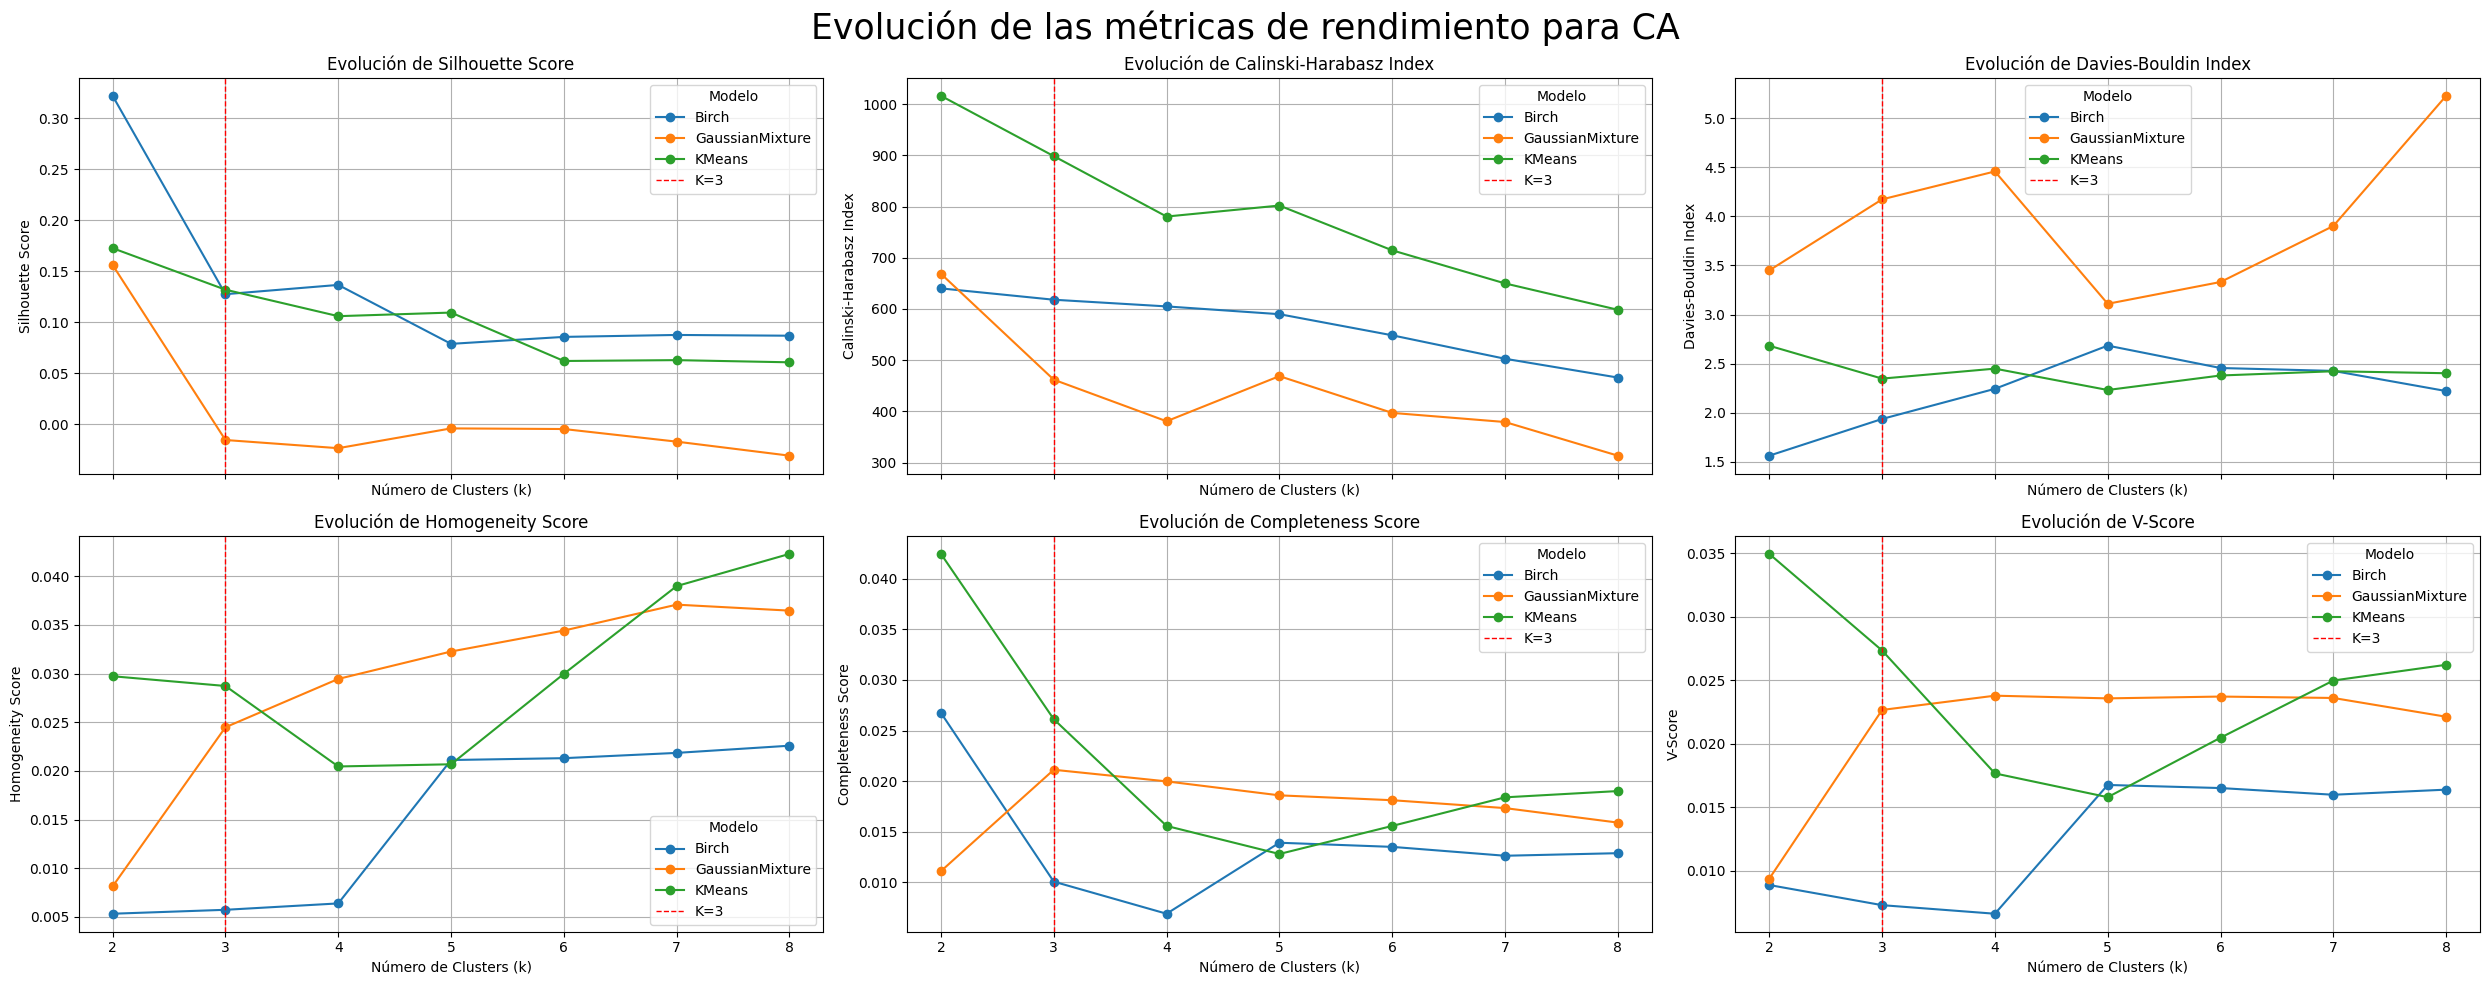

In [114]:
metrics = ["Silhouette Score",'Calinski-Harabasz Index','Davies-Bouldin Index', "Homogeneity Score", "Completeness Score", "V-Score"]
# Crear un subplot para cada métrica
fig, axes = plt.subplots(2, 3, figsize=(25, 10), sharex=True)
fig.suptitle('Evolución de las métricas de rendimiento para CA', fontsize=25)
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]
    for model in df_ca.index.get_level_values("Model").unique():
        # Filtrar datos del modelo actual
        subset = df_ca.loc[model]
        ax.plot(subset.index, subset[metric], marker="o", label=model)
    
    ax.axvline(x=3, color="red", linestyle="--", linewidth=1, label="K=3")
    
    ax.set_title(f"Evolución de {metric}")
    ax.set_xlabel("Número de Clusters (k)")
    ax.set_ylabel(metric)
    ax.legend(title="Modelo")
    ax.grid(True)


plt.tight_layout()
plt.show()


In this analysis, we evaluate the results for the "CANCER" category, where the classes are `malignant cancer`, `benign cancer`, and `non-cancer`. We focus on \( k=3 \), as this value reflects the expected tripartite structure of the data. Below are the main findings:

1. **Silhouette Score**: The **Birch** and **KMeans** models exhibit moderate performance at \( k=3 \), suggesting an acceptable separation between clusters. In contrast, **Gaussian Mixture** displays a much lower score, indicating poor separation among the three groups.

2. **Calinski-Harabasz Index**: At \( k=3 \), **KMeans** achieves the highest score, demonstrating its effectiveness in capturing the expected tripartite structure of the data. **Birch** also performs competitively, while **Gaussian Mixture** lags significantly behind.

3. **Davies-Bouldin Index**: For this metric, lower values indicate better-defined clusters. Both **Birch** and **KMeans** perform well at \( k=3 \), reflecting well-separated clusters. On the other hand, **Gaussian Mixture** has higher values, suggesting greater confusion and overlap between the groups.

4. **Homogeneity, Completeness, and V-Score**: These metrics reveal how well the clusters match the true classes (`malignant cancer`, `benign cancer`, and `non-cancer`). Across all models, these values are very low, indicating that none of the clustering algorithms fully capture the true structure of the data. Among the models, **Gaussian Mixture** slightly outperforms **KMeans** in these metrics, suggesting it better captures some aspects of the underlying class structure. However, the differences are marginal, and **Birch** performs the worst. Despite **Gaussian Mixture**'s relative advantage, the scores remain far from satisfactory, reflecting significant limitations in accurately representing the three categories.

### Conclusion
While \( k=3 \) is consistent with the expected structure of the data, the very low values for Homogeneity, Completeness, and V-Score demonstrate that the clustering models struggle to accurately reflect the true class distribution. **KMeans** performs the best in separation metrics such as Silhouette and Calinski-Harabasz, while **Gaussian Mixture** slightly outperforms in representing the true classes, albeit with very low scores. **Birch**, while competitive in some metrics, falls behind in capturing the class structure.

---

## Labels for K=4 

### Dzclass

In [115]:
df_dzclass=grouped_results.xs('dzclass', level='Label')
df_dzclass

Silhouette Score  Homogeneity Score  Completeness Score  \
Model           k                                                            
Birch           2          0.322074           0.017823            0.121979   
                3          0.127512           0.020959            0.050204   
                4          0.136605           0.023014            0.033882   
                5          0.078793           0.073363            0.065964   
                6          0.085623           0.073921            0.063938   
                7          0.087524           0.077162            0.060857   
                8          0.086779           0.077749            0.060507   
GaussianMixture 2          0.156198           0.030260            0.056343   
                3         -0.015463           0.069241            0.081554   
                4         -0.020885           0.077920            0.072656   
                5         -0.003958           0.085120            0.067068   
                6         -0.005135           0.088860            0.063765   
                7         -0.020423           0.118658            0.075900   
                8         -0.022671           0.115622            0.070704   
KMeans          2          0.169303           0.099898            0.190276   
                3          0.170749           0.097243            0.133553   
                4          0.136123           0.082058            0.083876   
                5          0.110628           0.090448            0.076584   
                6          0.113917           0.090786            0.072782   
                7          0.069024           0.113046            0.077014   
                8          0.058776           0.119374            0.071229   

                    V-Score  Calinski-Harabasz Index  Davies-Bouldin Index  
Model           k                                                           
Birch           2  0.031101               640.145298              1.563623  
                3  0.029572               617.989300              1.937114  
                4  0.027410               604.940821              2.244032  
                5  0.069467               589.775479              2.683604  
                6  0.068568               548.511877              2.455708  
                7  0.068047               502.720251              2.426202  
                8  0.068053               465.966552              2.221240  
GaussianMixture 2  0.039373               668.467437              3.449437  
                3  0.074895               461.747884              4.174995  
                4  0.075196               394.157957              4.367404  
                5  0.075023               470.462121              3.115969  
                6  0.074250               395.402885              3.341602  
                7  0.092581               373.573682              3.892093  
                8  0.087749               324.229953              3.820667  
KMeans          2  0.131012              1017.385448              2.715624  
                3  0.112542               832.824330              2.338067  
                4  0.082957               830.847269              2.168111  
                5  0.082940               801.911348              2.227384  
                6  0.080793               729.358028              2.102215  
                7  0.091614               671.511435              2.237809  
                8  0.089221               589.929063              2.453409

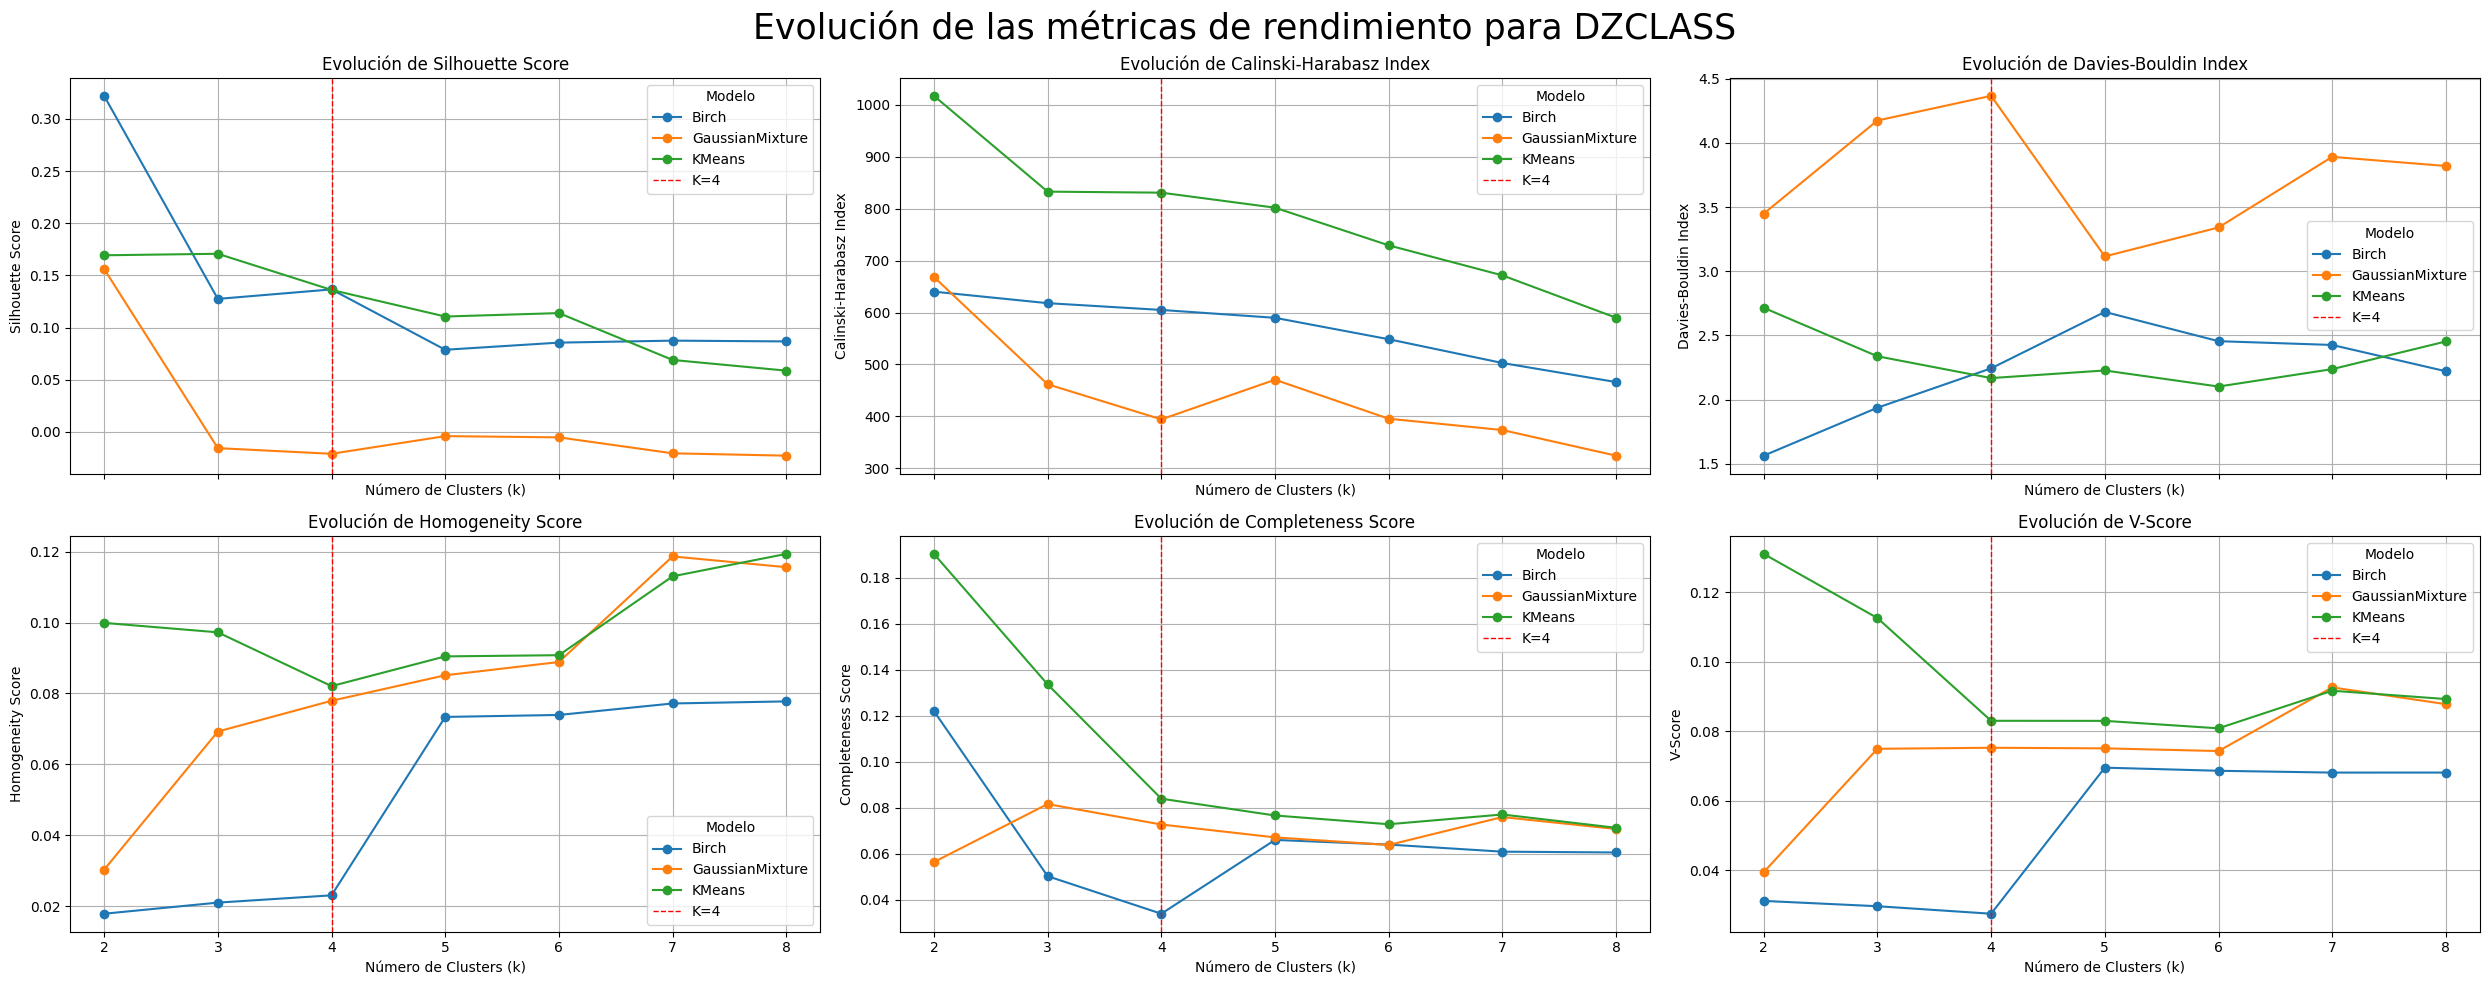

In [116]:
metrics = ["Silhouette Score",'Calinski-Harabasz Index','Davies-Bouldin Index', "Homogeneity Score", "Completeness Score", "V-Score"]
# Crear un subplot para cada métrica
fig, axes = plt.subplots(2, 3, figsize=(25, 10), sharex=True)
fig.suptitle('Evolución de las métricas de rendimiento para DZCLASS', fontsize=25)
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]
    for model in df_dzclass.index.get_level_values("Model").unique():
        # Filtrar datos del modelo actual
        subset = df_dzclass.loc[model]
        ax.plot(subset.index, subset[metric], marker="o", label=model)
    
    ax.axvline(x=4, color="red", linestyle="--", linewidth=1, label="K=4")
    ax.set_title(f"Evolución de {metric}")
    ax.set_xlabel("Número de Clusters (k)")
    ax.set_ylabel(metric)
    ax.legend(title="Modelo")
    ax.grid(True)


plt.tight_layout()
plt.show()


In this analysis, we evaluate the results for the “DZCLASS” category, which includes four classes corresponding to different disease groups. We focus on \( k=4 \), as this value reflects the expected structure of the data. Below are the main findings:

1. **Silhouette Score**: The **Birch** and **KMeans** models show moderate performance at \( k=4 \), indicating an acceptable level of separation between clusters. However, **Gaussian Mixture** presents a value close to zero, suggesting that the clusters generated by this model do not adequately separate the four categories.

2. **Calinski-Harabasz Index**: At \( k=4 \), **KMeans** achieves the best performance, suggesting it effectively captures the underlying structure of the data. **Birch** also performs adequately, though not as well as **KMeans**, while **Gaussian Mixture** shows significantly lower values, indicating poor group definition.

3. **Davies-Bouldin Index**: This metric further supports the findings, as **Birch** and **KMeans** exhibit low values at \( k=4 \), indicating well-defined clusters. In contrast, **Gaussian Mixture** presents high values, reflecting considerable overlap and confusion between clusters.

4. **Homogeneity, Completeness, and V-Score**: These metrics, which assess how well the clusters reflect the true classes, yield very low values across all models at \( k=4 \). Among the models:
   - **KMeans** achieves the highest scores, demonstrating a marginally better ability to capture the structure of the four disease classes. However, the values are still far from ideal.
   - **Gaussian Mixture** follows closely, with slightly lower performance compared to **Gaussian Mixture** but still competitive.
   - **Birch** lags significantly behind in these metrics, indicating that its clusters fail to represent the true class structure effectively.
   
   While the scores are objectively low, they represent the best results obtained so far in capturing the data, despite the ongoing limitations.

### Conclusion
While \( k=4 \) is consistent with the expected structure of the “DZCLASS” category, the very low values ​​for homogeneity, completeness, and V-score highlight significant challenges in accurately reflecting the actual class distribution. **KMeans** excels on separation-focused metrics such as Silhouette and Calinski-Harabasz and also shows marginal improvement over **Gaussian Mixture** on class representation-related metrics such as homogeneity, completeness, and V-score. **Birch** demonstrates weaker performance on most metrics.

---

## Labels para K=5

### Income

In [117]:
df_income=grouped_results.xs('income', level='Label')
df_income

Silhouette Score  Homogeneity Score  Completeness Score  \
Model           k                                                            
Birch           2          0.322074           0.002586            0.021968   
                3          0.127512           0.007059            0.020990   
                4          0.136605           0.007428            0.013577   
                5          0.078793           0.007811            0.008719   
                6          0.085623           0.007926            0.008511   
                7          0.087524           0.008399            0.008224   
                8          0.086779           0.008917            0.008615   
GaussianMixture 2          0.155908           0.000563            0.001299   
                3         -0.015469           0.000853            0.001247   
                4         -0.020961           0.001099            0.001272   
                5         -0.004146           0.005389            0.005264   
                6         -0.004658           0.006076            0.005459   
                7         -0.034298           0.006462            0.005425   
                8         -0.025865           0.005951            0.004593   
KMeans          2          0.170369           0.002237            0.005332   
                3          0.168009           0.002919            0.004972   
                4          0.119189           0.007568            0.009218   
                5          0.110879           0.008062            0.008474   
                6          0.113234           0.008309            0.008265   
                7          0.062828           0.023193            0.018624   
                8          0.061279           0.024198            0.018458   

                    V-Score  Calinski-Harabasz Index  Davies-Bouldin Index  
Model           k                                                           
Birch           2  0.004627               640.145298              1.563623  
                3  0.010565               617.989300              1.937114  
                4  0.009603               604.940821              2.244032  
                5  0.008240               589.775479              2.683604  
                6  0.008208               548.511877              2.455708  
                7  0.008311               502.720251              2.426202  
                8  0.008763               465.966552              2.221240  
GaussianMixture 2  0.000785               667.723733              3.452130  
                3  0.001013               461.887578              4.173888  
                4  0.001179               394.182484              4.363099  
                5  0.005326               468.695451              3.112265  
                6  0.005751               399.001906              3.326920  
                7  0.005898               355.230707              4.030435  
                8  0.005185               339.360157              3.926521  
KMeans          2  0.003152              1017.229244              2.704138  
                3  0.003678               833.144086              2.343553  
                4  0.008312               831.662516              2.457263  
                5  0.008263               801.873187              2.224337  
                6  0.008287               729.361952              2.103460  
                7  0.020659               650.076301              2.430247  
                8  0.020942               597.198968              2.409586

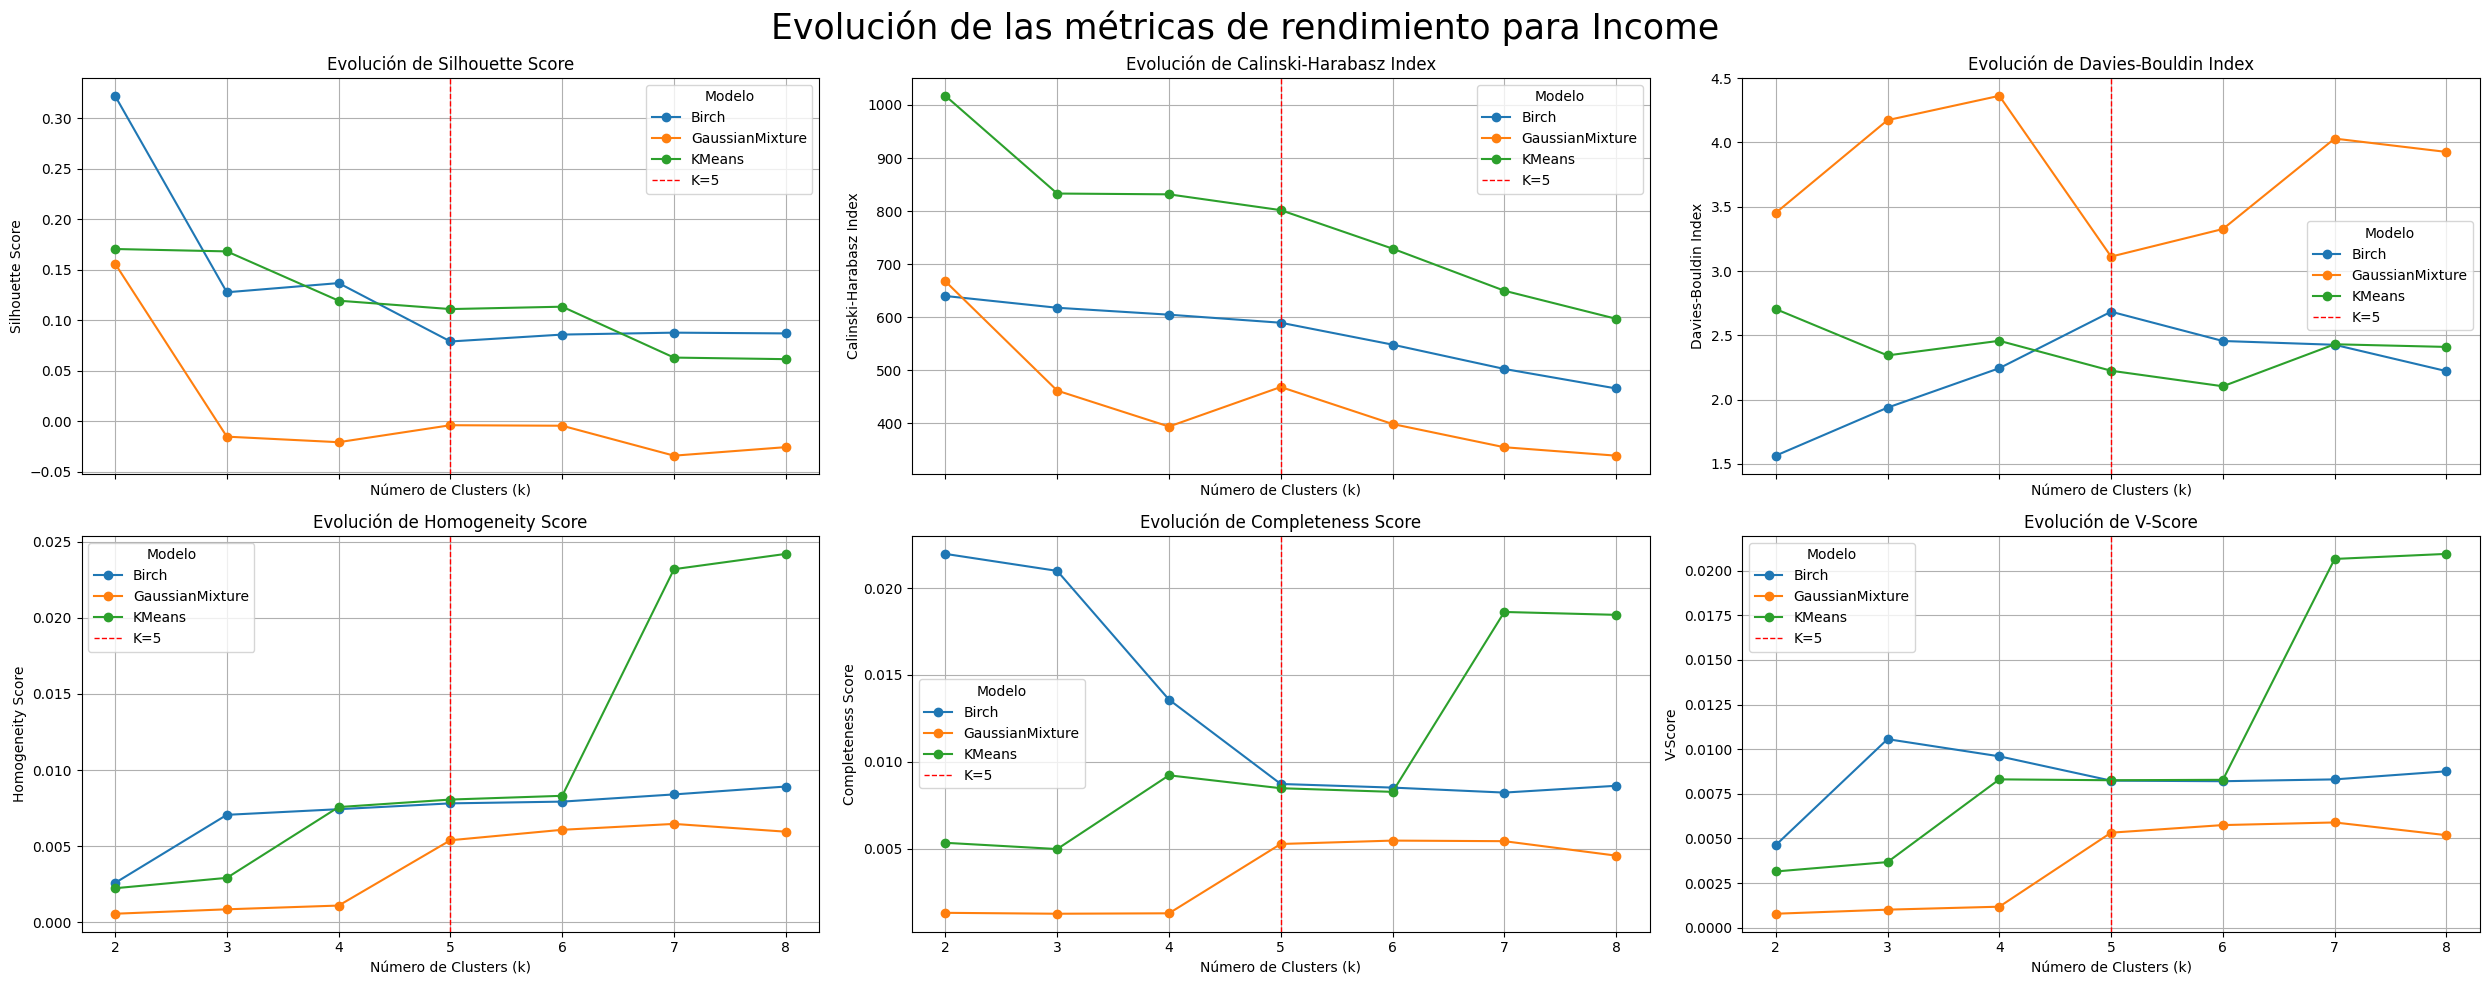

In [118]:
metrics = ["Silhouette Score",'Calinski-Harabasz Index','Davies-Bouldin Index', "Homogeneity Score", "Completeness Score", "V-Score"]
# Crear un subplot para cada métrica
fig, axes = plt.subplots(2, 3, figsize=(25, 10), sharex=True)
fig.suptitle('Evolución de las métricas de rendimiento para Income', fontsize=25)
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]
    for model in df_income.index.get_level_values("Model").unique():
        # Filtrar datos del modelo actual
        subset = df_income.loc[model]
        ax.plot(subset.index, subset[metric], marker="o", label=model)
    
    ax.axvline(x=5, color="red", linestyle="--", linewidth=1, label="K=5")
    ax.set_title(f"Evolución de {metric}")
    ax.set_xlabel("Número de Clusters (k)")
    ax.set_ylabel(metric)
    ax.legend(title="Modelo")
    ax.grid(True)


plt.tight_layout()
plt.show()

In this analysis, we evaluate the results of the models for the "INCOME" category, where the classes correspond to five distinct income ranges. We focus on \( k=5 \), as this value reflects the expected structure of the data. Below are the main findings:

1. **Silhouette Score**: Both **Birch** and **KMeans** show moderate performance at \( k=5 \), with similar values ​​indicating an acceptable separation between the clusters. However, **Gaussian Mixture** presents values ​​close to zero, reflecting less clarity in the separation of the five categories.

2. **Calinski-Harabasz Index**: At \( k=5 \), **KMeans** stands out as the best-performing model, suggesting it is better able to identify the underlying structure of the data based on income ranges. **Birch** delivers competitive but slightly inferior performance compared to **KMeans**, while **Gaussian Mixture** performs significantly worse, indicating weaker clustering ability.

3. **Davies-Bouldin Index**: This metric supports the earlier results. Both **Birch** and **KMeans** achieve low values ​​at \( k=5 \), indicating well-defined clusters. In contrast, **Gaussian Mixture** presents significantly higher values, reflecting substantial overlap and confusion among the clusters it forms.

4. **Homogeneity, Completeness, and V-Score**: These metrics, which evaluate how well the clusters match the true income classes, reveal very low values ​​for all models at \( k=5 \). Among the models:
 - **KMeans** achieves the highest scores, indicating it is marginally better at capturing the structure of the five income categories. However, the values ​​remain far from ideal.
 - **Birch** follows, with acceptable but still limited performance in representing the true classes.
 - **Gaussian Mixture** underperforms in these metrics, reflecting its inability to effectively capture the income range structure.


### Conclusion
While \( k=5 \) aligns with the expected structure of the "INCOME" category, the very low values ​​for Homogeneity, Completeness, and V-Score indicate significant difficulties in accurately representing the true class distribution. **KMeans** demonstrates the strongest overall performance, excelling in both separation metrics and its ability to represent the true classes. **Birch** performs adequately but falls short compared to **KMeans**, while **Gaussian Mixture** struggles across most metrics, particularly in cluster definition.

---

### RACE

In [119]:
df_race=grouped_results.xs('race', level='Label')
df_race

Silhouette Score  Homogeneity Score  Completeness Score  \
Model           k                                                            
Birch           2          0.322074           0.003598            0.014051   
                3          0.127512           0.005283            0.007221   
                4          0.136605           0.006563            0.005514   
                5          0.078793           0.007192            0.003690   
                6          0.085623           0.008364            0.004128   
                7          0.087524           0.008510            0.003830   
                8          0.086779           0.008672            0.003851   
GaussianMixture 2          0.156331           0.002514            0.002672   
                3         -0.015433           0.004615            0.003099   
                4         -0.011046           0.005727            0.002835   
                5         -0.003892           0.010013            0.004502   
                6         -0.046203           0.011523            0.004733   
                7         -0.029687           0.009073            0.003420   
                8         -0.047788           0.010908            0.003739   
KMeans          2          0.169225           0.004010            0.004359   
                3          0.124134           0.009169            0.006804   
                4          0.119208           0.009588            0.005368   
                5          0.109346           0.008426            0.004064   
                6          0.063894           0.009997            0.004058   
                7          0.066992           0.011035            0.004278   
                8          0.068458           0.010647            0.003787   

                    V-Score  Calinski-Harabasz Index  Davies-Bouldin Index  
Model           k                                                           
Birch           2  0.005729               640.145298              1.563623  
                3  0.006102               617.989300              1.937114  
                4  0.005993               604.940821              2.244032  
                5  0.004877               589.775479              2.683604  
                6  0.005528               548.511877              2.455708  
                7  0.005282               502.720251              2.426202  
                8  0.005334               465.966552              2.221240  
GaussianMixture 2  0.002591               668.659740              3.448821  
                3  0.003708               461.480449              4.170017  
                4  0.003792               435.024576              3.872569  
                5  0.006212               470.675682              3.115343  
                6  0.006710               408.323717              3.676548  
                7  0.004967               358.666406              4.231998  
                8  0.005569               328.301775              4.020573  
KMeans          2  0.004177              1017.380950              2.715431  
                3  0.007812               832.299287              2.753155  
                4  0.006882               831.668213              2.457377  
                5  0.005483               801.928448              2.231512  
                6  0.005772               714.434956              2.374473  
                7  0.006166               671.431426              2.240473  
                8  0.005586               624.507055              2.283024

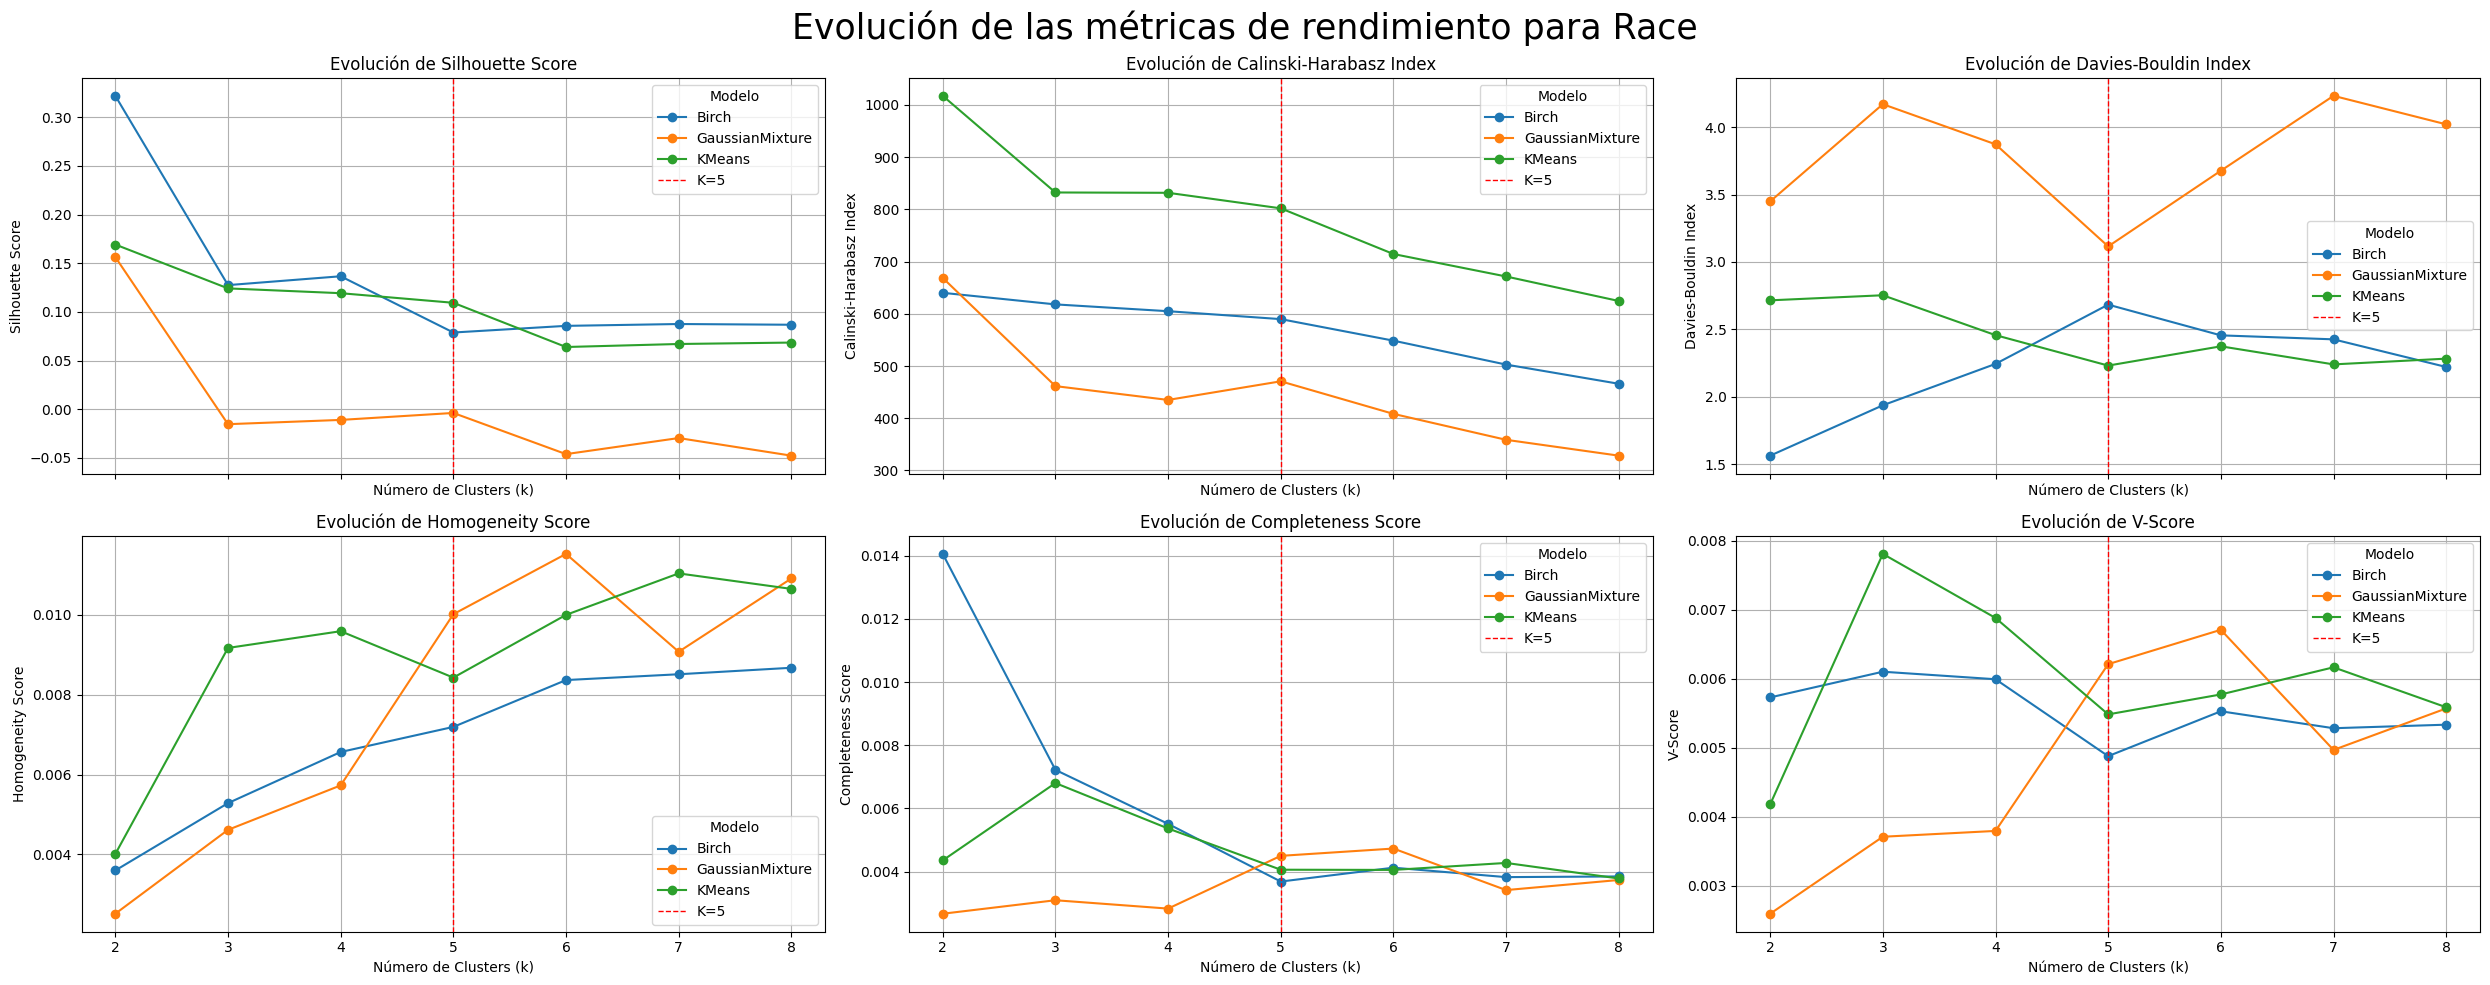

In [120]:
metrics = ["Silhouette Score",'Calinski-Harabasz Index','Davies-Bouldin Index', "Homogeneity Score", "Completeness Score", "V-Score"]
# Crear un subplot para cada métrica
fig, axes = plt.subplots(2, 3, figsize=(25, 10), sharex=True)
fig.suptitle('Evolución de las métricas de rendimiento para Race', fontsize=25)
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]
    for model in df_race.index.get_level_values("Model").unique():
        # Filtrar datos del modelo actual
        subset = df_race.loc[model]
        ax.plot(subset.index, subset[metric], marker="o", label=model)
    
    ax.axvline(x=5, color="red", linestyle="--", linewidth=1, label="K=5")
    ax.set_title(f"Evolución de {metric}")
    ax.set_xlabel("Número de Clusters (k)")
    ax.set_ylabel(metric)
    ax.legend(title="Modelo")
    ax.grid(True)


plt.tight_layout()
plt.show()


In this analysis, we evaluate the results of the models for the category "RACE," which includes five distinct race categories. We focus on \( k=5 \), as this value reflects the expected structure of the data.

1. **Silhouette Score**: The **Birch** and **KMeans** models show moderate performance at \( k=5 \), with similar values indicating an acceptable level of separation between the clusters. In contrast, **Gaussian Mixture** has values close to zero, suggesting a lack of clarity in the separation of the five categories.

2. **Calinski-Harabasz Index**: At \( k=5 \), **KMeans** achieves the best performance, demonstrating its ability to more effectively capture the underlying structure of the data. **Birch** also performs adequately, although its results are lower than those of **KMeans**. **Gaussian Mixture**, on the other hand, presents significantly lower values, reflecting greater challenges in identifying the expected structure.

3. **Davies-Bouldin Index**: This metric supports the findings from the Calinski-Harabasz Index. Both **Birch** and **KMeans** achieve low values at \( k=5 \), indicating well-defined clusters. In contrast, **Gaussian Mixture** has high values, indicating confusion and overlap between the generated groups.

4. **Homogeneity, Completeness, and V-Score**: These metrics, which measure how well the clusters reflect the true race categories, show very low values for all models at \( k=5 \). Among the models:
   - **KMeans** achieves the highest scores, indicating it is slightly better at capturing the structure of the five categories. However, the values remain far from ideal, underscoring significant limitations.
   - **Birch** follows with moderate but lower performance compared to **KMeans**.
   - **Gaussian Mixture** has the weakest performance, reflecting its inability to effectively represent the structure of the race categories.



5. **V-Score**: In terms of V-Score, which combines Homogeneity and Completeness, **KMeans** outperforms the other models, confirming its relative effectiveness in representing the structure of the data. **Birch** provides acceptable performance, while **Gaussian Mixture** continues to show limitations.

### Conclusion
While \( k=5 \) aligns with the expected structure of the "RACE" category, the very low values for Homogeneity, Completeness, and V-Score indicate that clustering models still struggle to accurately represent the true class distribution. **KMeans** demonstrates the strongest performance overall, excelling in both separation-focused metrics and in representing the true classes. **Birch** performs adequately but falls short compared to **KMeans**, and **Gaussian Mixture** exhibits the weakest performance across most metrics.


## Labels para k=6

### Sfdm2

In [121]:
df_sfdm2=grouped_results.xs('sfdm2', level='Label')
df_sfdm2

Silhouette Score  Homogeneity Score  Completeness Score  \
Model           k                                                            
Birch           2          0.322074           0.008598            0.071807   
                3          0.127512           0.025087            0.073328   
                4          0.136605           0.026552            0.047702   
                5          0.078793           0.038345            0.042073   
                6          0.085623           0.040270            0.042504   
                7          0.087524           0.040544            0.039020   
                8          0.086779           0.041134            0.039064   
GaussianMixture 2          0.156148           0.010880            0.024714   
                3         -0.015609           0.016170            0.023242   
                4         -0.020960           0.022168            0.025220   
                5         -0.004081           0.028288            0.027158   
                6         -0.030462           0.036474            0.032531   
                7         -0.048595           0.037721            0.030126   
                8         -0.025626           0.036644            0.027799   
KMeans          2          0.169296           0.020103            0.046725   
                3          0.173316           0.020754            0.035081   
                4          0.119189           0.046014            0.055091   
                5          0.109709           0.043321            0.044701   
                6          0.061882           0.044044            0.038077   
                7          0.102387           0.047329            0.039895   
                8          0.067562           0.050231            0.038171   

                    V-Score  Calinski-Harabasz Index  Davies-Bouldin Index  
Model           k                                                           
Birch           2  0.015357               640.145298              1.563623  
                3  0.037384               617.989300              1.937114  
                4  0.034115               604.940821              2.244032  
                5  0.040123               589.775479              2.683604  
                6  0.041357               548.511877              2.455708  
                7  0.039767               502.720251              2.426202  
                8  0.040072               465.966552              2.221240  
GaussianMixture 2  0.015108               668.679670              3.449177  
                3  0.019072               461.845610              4.171743  
                4  0.023596               394.257795              4.363688  
                5  0.027712               468.441766              3.108617  
                6  0.034390               407.661380              3.307304  
                7  0.033498               353.803634              3.583455  
                8  0.031615               327.974725              3.852654  
KMeans          2  0.028111              1017.386280              2.715611  
                3  0.026080               832.912629              2.337698  
                4  0.050145               831.662516              2.457263  
                5  0.044000               801.936472              2.231135  
                6  0.040844               714.283676              2.383328  
                7  0.043295               639.754320              2.351880  
                8  0.043378               624.394752              2.276633

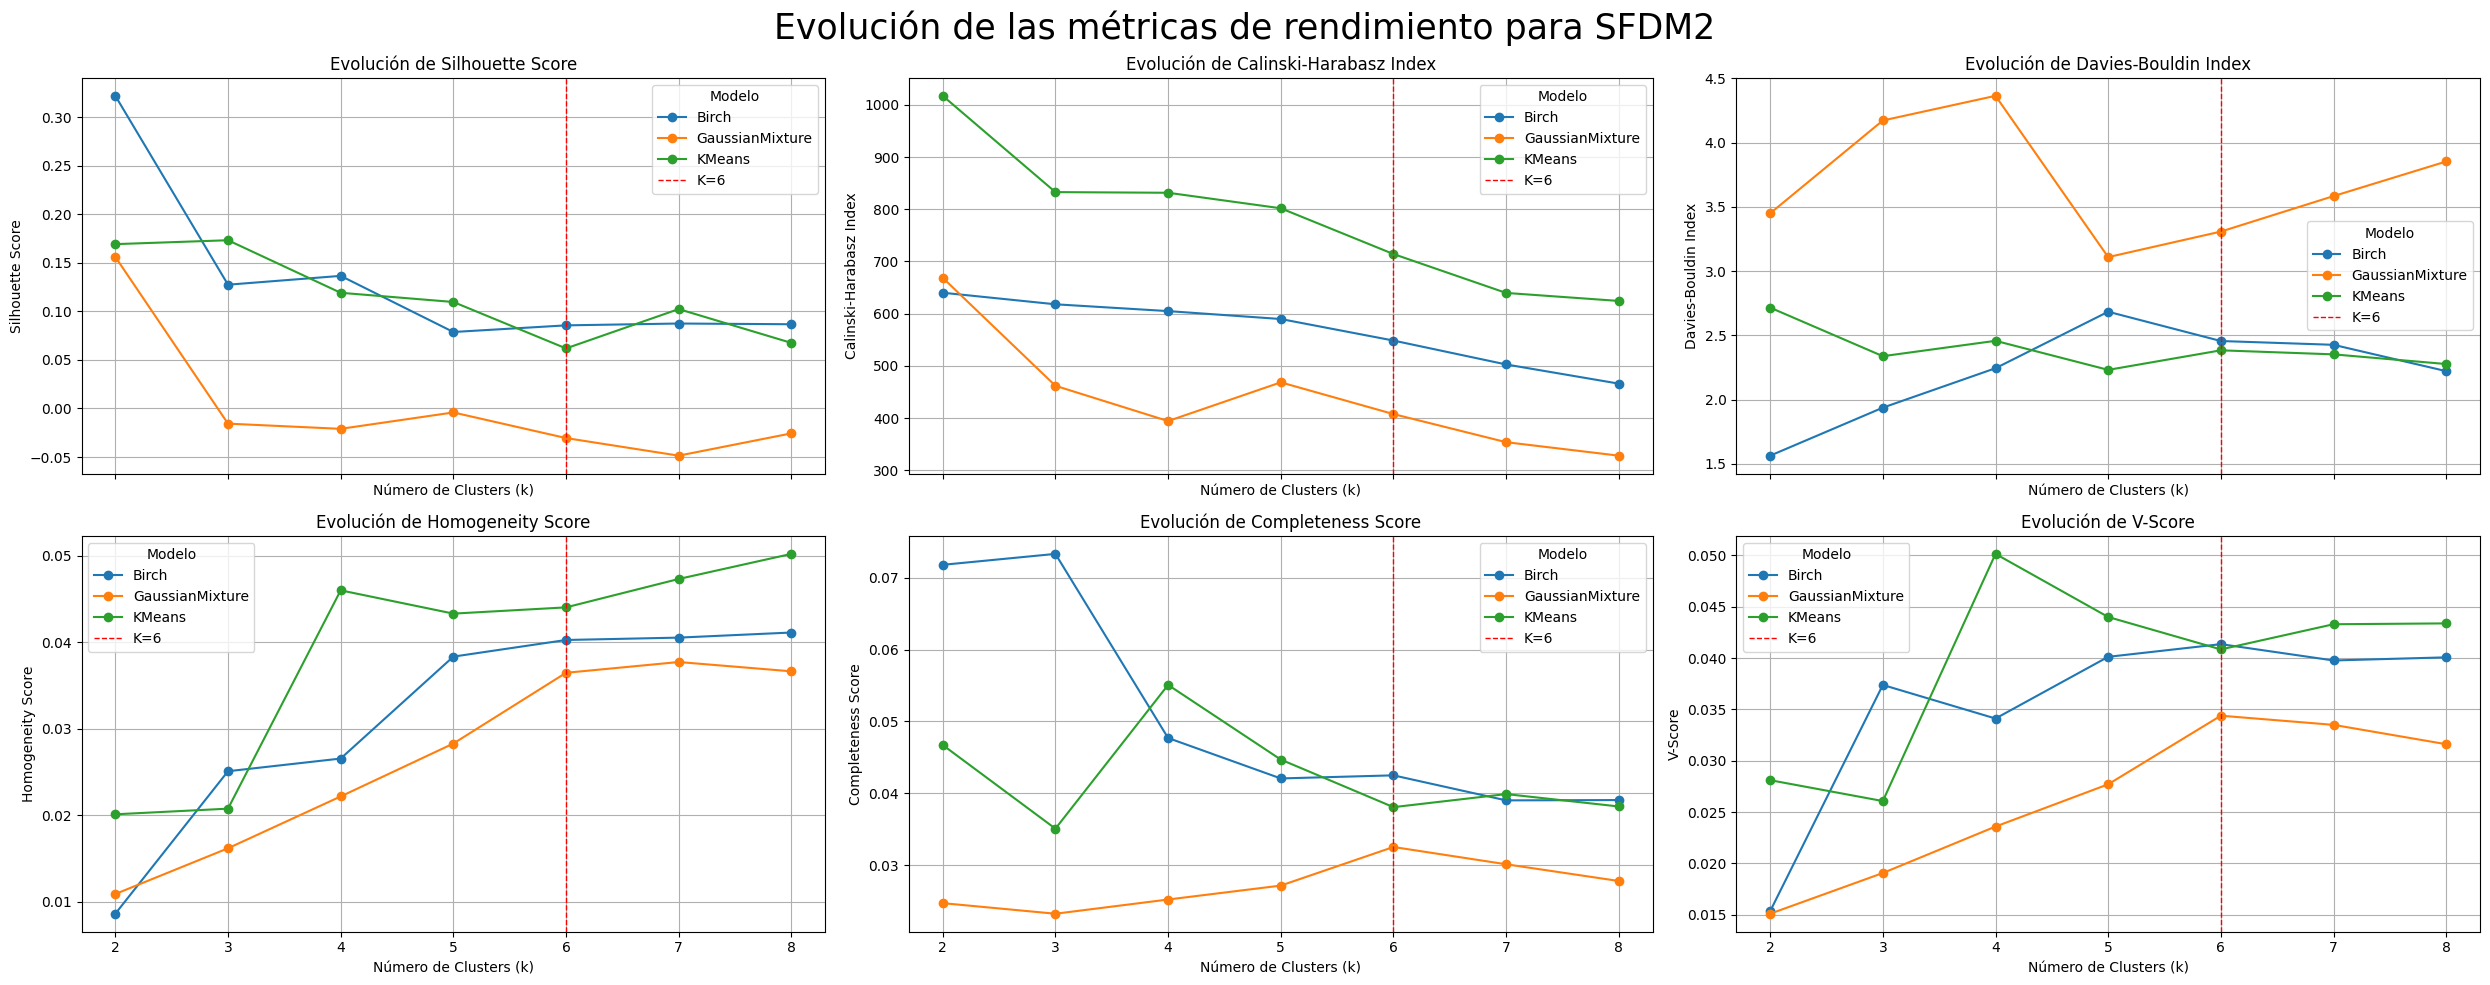

In [122]:
metrics = ["Silhouette Score",'Calinski-Harabasz Index','Davies-Bouldin Index', "Homogeneity Score", "Completeness Score", "V-Score"]
# Crear un subplot para cada métrica
fig, axes = plt.subplots(2, 3, figsize=(25, 10), sharex=True)
fig.suptitle('Evolución de las métricas de rendimiento para SFDM2', fontsize=25)
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]
    for model in df_sfdm2.index.get_level_values("Model").unique():
        # Filtrar datos del modelo actual
        subset = df_sfdm2.loc[model]
        ax.plot(subset.index, subset[metric], marker="o", label=model)
    
    ax.axvline(x=6, color="red", linestyle="--", linewidth=1, label="K=6")
    ax.set_title(f"Evolución de {metric}")
    ax.set_xlabel("Número de Clusters (k)")
    ax.set_ylabel(metric)
    ax.legend(title="Modelo")
    ax.grid(True)


plt.tight_layout()
plt.show()

In this analysis we evaluate the results for the “SFDM2” category, which includes six distinct categories of clinical outputs. We focus on \( k=6 \), as this value reflects the expected structure of the data. The main findings are presented below:

1. **Silhouette Score**: The **Birch** and **KMeans** models show moderate performance at \( k=6 \), with similar values ​​reflecting an acceptable separation between the clusters. In contrast, **Gaussian Mixture** presents values ​​close to zero, indicating less clarity in the separation of the six categories.

2. **Calinski-Harabasz Index**: At \( k=6 \), **KMeans** stands out as the best performing model, suggesting that it better identifies the underlying structure of the data. **Birch** also shows acceptable but inferior performance, while **Gaussian Mixture** obtains considerably lower results, reflecting difficulties in capturing the expected structure.

3. **Davies-Bouldin Index**: This index reinforces the previous trend. Both **Birch** and **KMeans** achieve low values ​​at \( k=6 \), indicating well-defined and coherent clusters. In contrast, **Gaussian Mixture** presents high values, reflecting greater confusion between the formed groups.

4. **Homogeneity, Completeness and V-Score**: These metrics, which evaluate how well the clusters reflect the real classes, show very low values ​​for all models at \( k=6 \). However:
- **KMeans** achieves the highest scores, indicating that, although to a limited extent, it is the model that best captures the structure of the six clinical categories.
- **Birch** follows in second place, with a moderate but clearly inferior performance to **KMeans**.
- **Gaussian Mixture** has the worst performance, reflecting a significant inability to represent the class structure.


5. **V-Score**: In terms of **V-Score**, which combines Homogeneity and Completeness, **KMeans** clearly leads, confirming its relative ability to represent the structure of the data. **Birch** performs acceptably, while **Gaussian Mixture** remains limited.

### Conclusion
While \( k=6 \) is consistent with the expected structure of the "SFDM2" category, the very low values ​​of Homogeneity, Completeness, and V-Score demonstrate that clustering models still face significant difficulties in accurately reflecting the actual distribution of classes. **KMeans** is positioned as the most robust model, standing out both in separation metrics and in representation of the actual classes. **Birch** follows closely behind with acceptable performance, and **Gaussian Mixture** clearly lags behind.

---


## Labels para K=8

### Dzgroup

In [123]:
df_dzgroup=grouped_results.xs('dzgroup', level='Label')
df_dzgroup

Silhouette Score  Homogeneity Score  Completeness Score  \
Model           k                                                            
Birch           2          0.322074           0.011944            0.125414   
                3          0.127512           0.014512            0.053330   
                4          0.136605           0.016777            0.037894   
                5          0.078793           0.051687            0.071300   
                6          0.085623           0.054392            0.072177   
                7          0.087524           0.057293            0.069323   
                8          0.086779           0.057946            0.069185   
GaussianMixture 2          0.150958           0.022912            0.064690   
                3         -0.015455           0.052462            0.094813   
                4         -0.020928           0.059888            0.085672   
                5         -0.004116           0.066536            0.080312   
                6         -0.008838           0.073318            0.081064   
                7         -0.046318           0.073848            0.074737   
                8         -0.020238           0.092755            0.084912   
KMeans          2          0.169390           0.067509            0.197328   
                3          0.131853           0.064238            0.122166   
                4          0.120387           0.056931            0.085561   
                5          0.109468           0.062540            0.081035   
                6          0.064084           0.080355            0.087764   
                7          0.062325           0.084990            0.083986   
                8          0.058291           0.091014            0.083593   

                    V-Score  Calinski-Harabasz Index  Davies-Bouldin Index  
Model           k                                                           
Birch           2  0.021811               640.145298              1.563623  
                3  0.022816               617.989300              1.937114  
                4  0.023257               604.940821              2.244032  
                5  0.059930               589.775479              2.683604  
                6  0.062035               548.511877              2.455708  
                7  0.062737               502.720251              2.426202  
                8  0.063069               465.966552              2.221240  
GaussianMixture 2  0.033838               666.264859              3.463012  
                3  0.067548               461.946886              4.171045  
                4  0.070497               394.165189              4.365813  
                5  0.072778               468.647908              3.110530  
                6  0.076996               419.335349              3.384136  
                7  0.074290               354.478622              3.761303  
                8  0.088660               335.919587              3.786337  
KMeans          2  0.100601              1017.387890              2.715340  
                3  0.084201               898.464919              2.348629  
                4  0.068370               831.561874              2.462134  
                5  0.070596               801.928193              2.232364  
                6  0.083896               714.422917              2.372533  
                7  0.084485               650.095886              2.430011  
                8  0.087146               589.136203              2.391874

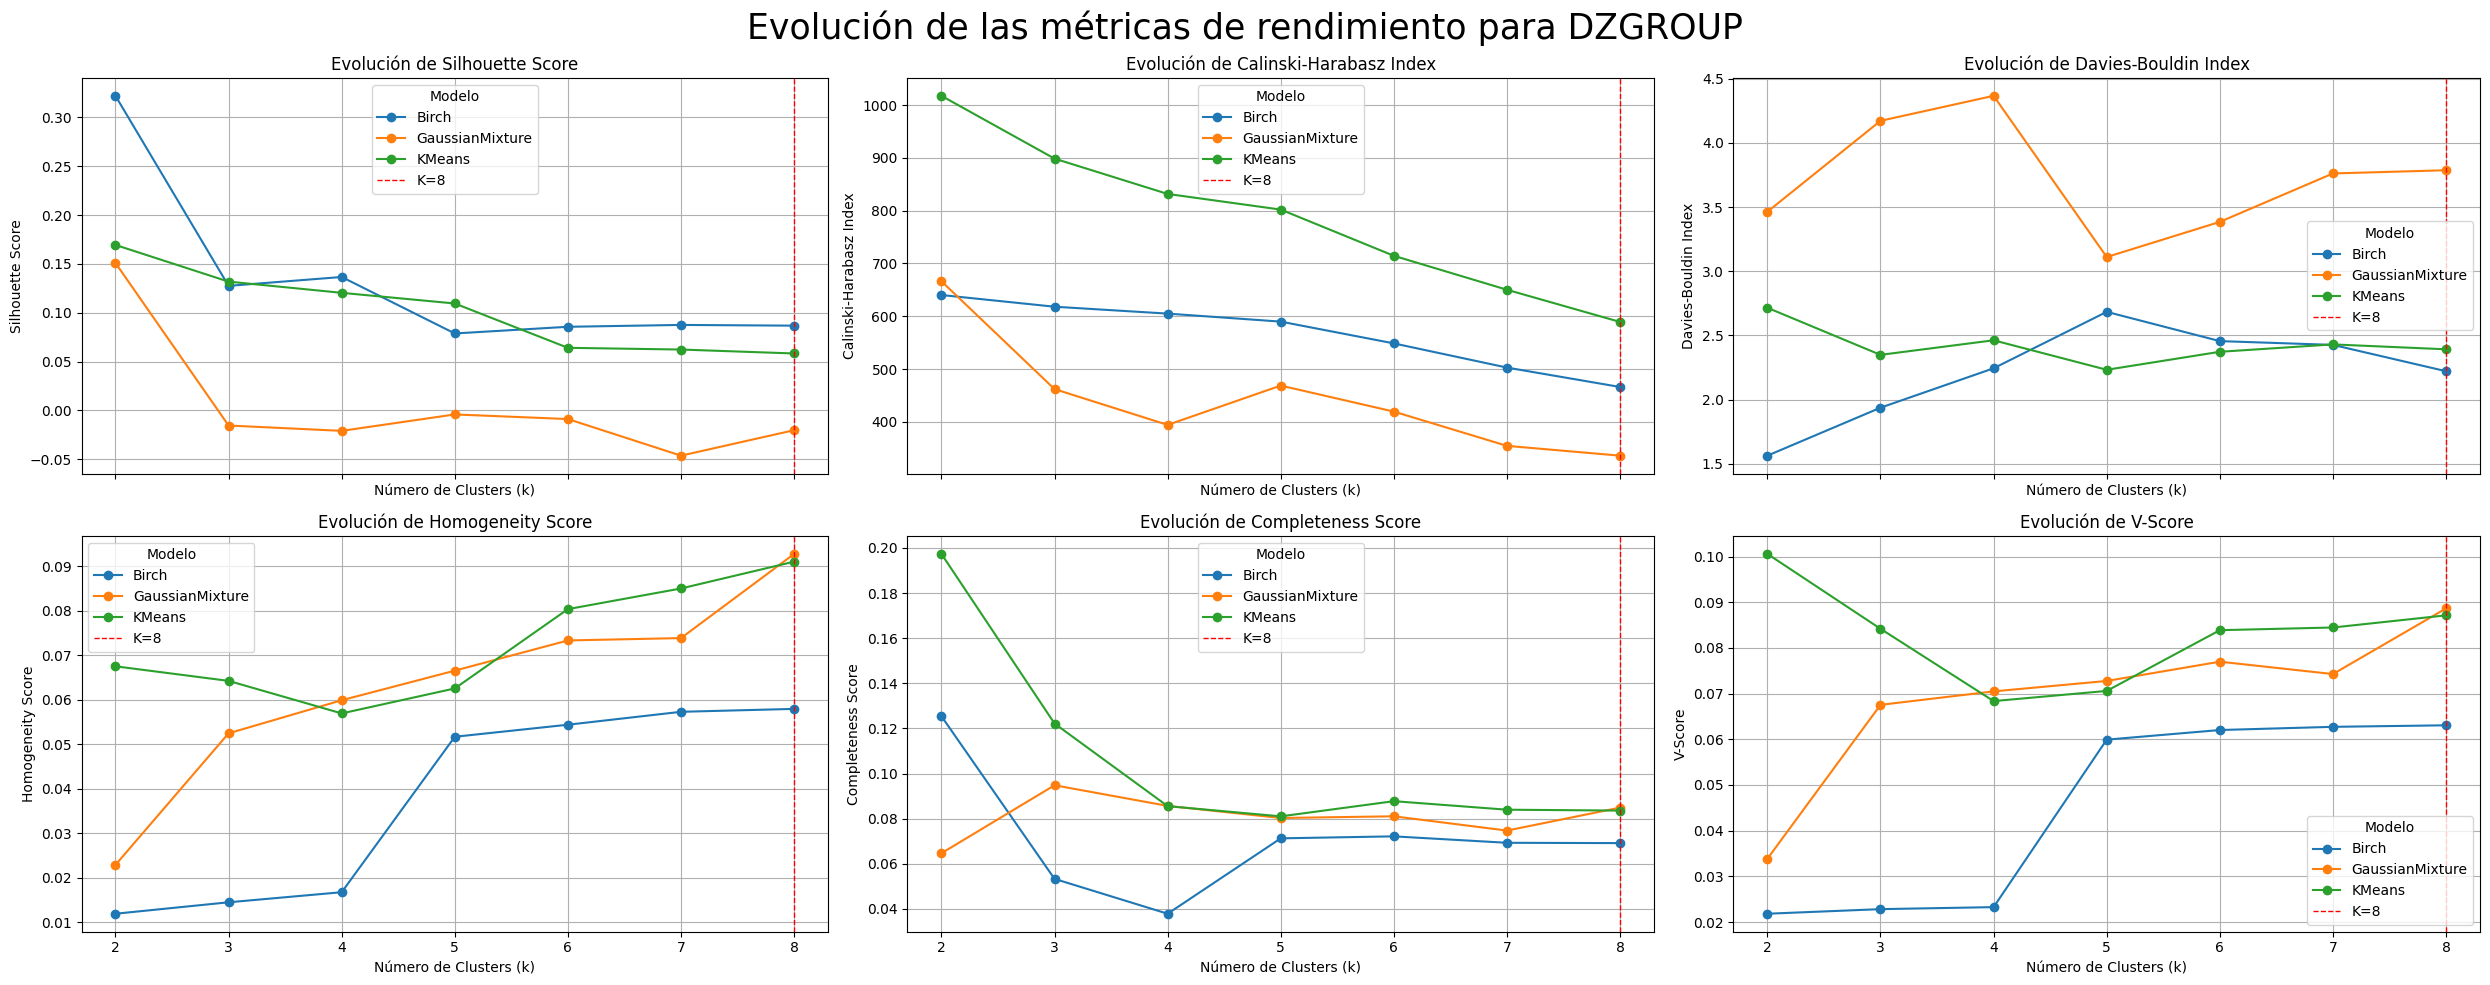

In [124]:
metrics = ["Silhouette Score",'Calinski-Harabasz Index','Davies-Bouldin Index', "Homogeneity Score", "Completeness Score", "V-Score"]
# Crear un subplot para cada métrica
fig, axes = plt.subplots(2, 3, figsize=(25, 10), sharex=True)
fig.suptitle('Evolución de las métricas de rendimiento para DZGROUP', fontsize=25)
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]
    for model in df_dzgroup.index.get_level_values("Model").unique():
        # Filtrar datos del modelo actual
        subset = df_dzgroup.loc[model]
        ax.plot(subset.index, subset[metric], marker="o", label=model)
    
    ax.axvline(x=8, color="red", linestyle="--", linewidth=1, label="K=8")
    ax.set_title(f"Evolución de {metric}")
    ax.set_xlabel("Número de Clusters (k)")
    ax.set_ylabel(metric)
    ax.legend(title="Modelo")
    ax.grid(True)


plt.tight_layout()
plt.show()



The **"DZGROUP"** category includes eight distinct classes, reflected in \( k=8 \), which corresponds to the expected structure of the data. Below are the main findings based on the evaluated metrics:

1.**Silhouette Score**
- **Birch** and **KMeans** show moderate performance in \( k=8 \), with similar values ​​indicating an acceptable separation between the clusters.
- **Gaussian Mixture**, on the other hand, presents values ​​close to zero, reflecting a clear difficulty in achieving an adequate separation of the eight categories.

2.**Calinski-Harabasz Index**
- **KMeans** stands out as the best performing model in \( k=8 \), suggesting that it more effectively identifies the underlying structure of the data.
- **Birch** also has a reasonable performance, although lower than **KMeans**.
- **Gaussian Mixture** scores the lowest in this metric, indicating greater problems in capturing the expected structure.

3.**Davies-Bouldin Index**
- This index reinforces the previous findings. Both **Birch** and **KMeans** score low in \( k=8 \), indicating well-defined and consistent clusters.
- **Gaussian Mixture**, however, scores high, reflecting confusion and overlap between the formed clusters.

4.**Homogeneity, Completeness and V-Score**
These metrics, which assess how well the clusters reflect the real classes, have low values ​​overall. However:
- **KMeans** leads in these metrics, scoring the best in \( k=8 \). Although the scores are low, they indicate that the model is the most effective in partially capturing the structure of the classes.
- **Gaussian Mixture** follows closely behind **KMeans**, with acceptable but inferior performance.
- **Birch** has the most limited performance on these metrics, indicating that it fails to accurately capture the underlying classes.

#### **Conclusion**
Although \( k=8 \) is consistent with the expected class structure, the metrics indicate that clustering models still face significant challenges in accurately reflecting the actual class distribution. However:
- **KMeans** is the most robust model, excelling in both separation metrics and representation of the actual classes.
- **Gaussian Mixture** offers reasonable performance, although inferior to **KMeans**.
- **Birch** shows acceptable results on separation metrics, but its ability to capture the class structure is limited.

# 🟢 USE OF DBSCAN

The objective of this analysis is to evaluate whether the DBSCAN algorithm, with various combinations of hyperparameters, is able to identify a number of clusters that matches that of the target column we are studying. This will allow us to determine whether the clustering model can play a role similar to that of a classifier, grouping observations in a manner consistent with the categories of the target variable. This process will be monitored using metrics that assess the internal and external quality of the clusters.

In [125]:
# Función para evaluar DBSCAN con métricas adicionales
def evaluate_dbscan(epsilon, min_samples, X, y):
    algorithm = DBSCAN(eps=epsilon, min_samples=min_samples, metric='euclidean')
    y_pred = algorithm.fit_predict(X)
    
    # Calcular métricas
    # Verifica si hay más de un valor único en las predicciones de clúster. 
    # Si hay más de un valor (es decir, al menos dos clústeres diferentes), 
    # se calcula la métrica. Si no, se devuelve -1, indicando que la métrica no es válida o no puede ser calculada.

    silhouette = silhouette_score(X, y_pred) if len(set(y_pred)) - (1 if -1 in y_pred else 0) > 1 else -1  # el custer -1 es aquel que se asigna a los outliers
    calinski_harabasz = calinski_harabasz_score(X, y_pred) if len(set(y_pred)) - (1 if -1 in y_pred else 0) > 1 else -1  # el custer -1 es aquel que se asigna a los outliers
    davies_bouldin = davies_bouldin_score(X, y_pred) if len(set(y_pred)) - (1 if -1 in y_pred else 0) > 1 else -1  # el custer -1 es aquel que se asigna a los outliers
    
    # Métricas dependientes de las etiquetas reales
    homogeneity = homogeneity_score(y, y_pred) if len(set(y_pred)) > 1 else -1
    completeness = completeness_score(y, y_pred) if len(set(y_pred)) > 1 else -1
    v_score = v_measure_score(y, y_pred) if len(set(y_pred)) > 1 else -1
    
    # Número de clusters encontrados (excluyendo ruido, -1)
    n_clusters = len(set(y_pred)) - (1 if -1 in y_pred else 0)  
    
    return {
        'Silhouette Score': silhouette,
        'Homogeneity Score': homogeneity,
        'Completeness Score': completeness,
        'V-Score': v_score,
        'Calinski-Harabasz Index': calinski_harabasz,
        'Davies-Bouldin Index': davies_bouldin,
        'n_clusters': n_clusters,  # Agregado número de clusters
        'eps': epsilon,
        'min_samples': min_samples
    }

# Evaluar DBSCAN para diferentes valores de epsilon y min_samples
eps_values = [0.5, 1.0, 1.5]  # Valores de epsilon
min_samples_values = [3, 5, 10]  # Valores de min_samples

results = []

# Iterar sobre los conjuntos de etiquetas y parámetros
for col_name, y in zip(df_categorical.columns, labels):  # Conjuntos de etiquetas
    for eps in eps_values:
        for min_samples in min_samples_values:
            metrics = evaluate_dbscan(eps, min_samples, data_reduced, y)
            metrics['Model'] = 'DBSCAN'
            metrics['Label'] = col_name
            results.append(metrics)

# Convertir a DataFrame
results_df = pd.DataFrame(results)

# Agrupar resultados para resumen
grouped_results = results_df.groupby(['Model', 'Label', 'eps', 'min_samples']).agg({
    'Silhouette Score': 'mean',
    'Homogeneity Score': 'mean',
    'Completeness Score': 'mean',
    'V-Score': 'mean',
    'Calinski-Harabasz Index': 'mean',
    'Davies-Bouldin Index': 'mean',
    'n_clusters': 'mean'  # Agregado promedio del número de clusters
})

# Mostrar resultados agrupados
grouped_results


Silhouette Score  Homogeneity Score  \
Model  Label eps min_samples                                        
DBSCAN ca    0.5 3                   -1.000000          -1.000000   
                 5                   -1.000000          -1.000000   
                 10                  -1.000000          -1.000000   
             1.0 3                   -0.341336           0.025024   
                 5                   -0.281544           0.017859   
...                                        ...                ...   
       sfdm2 1.0 5                   -0.281544           0.004920   
                 10                  -0.260742           0.001309   
             1.5 3                   -0.322098           0.021633   
                 5                   -0.227380           0.017242   
                 10                  -0.122855           0.016122   

                              Completeness Score   V-Score  \
Model  Label eps min_samples                                 
DBSCAN ca    0.5 3                     -1.000000 -1.000000   
                 5                     -1.000000 -1.000000   
                 10                    -1.000000 -1.000000   
             1.0 3                      0.121050  0.041474   
                 5                      0.141278  0.031709   
...                                          ...       ...   
       sfdm2 1.0 5                      0.064848  0.009146   
                 10                     0.045404  0.002544   
             1.5 3                      0.052054  0.030564   
                 5                      0.048579  0.025451   
                 10                     0.051958  0.024608   

                              Calinski-Harabasz Index  Davies-Bouldin Index  \
Model  Label eps min_samples                                                  
DBSCAN ca    0.5 3                          -1.000000             -1.000000   
                 5                          -1.000000             -1.000000   
                 10                         -1.000000             -1.000000   
             1.0 3                           3.211659              1.917951   
                 5                           7.131059              2.098907   
...                                               ...                   ...   
       sfdm2 1.0 5                           7.131059              2.098907   
                 10                          6.578309              2.420351   
             1.5 3                          15.239700              1.918858   
                 5                          66.755465              2.305333   
                 10                        145.121230              2.513256   

                              n_clusters  
Model  Label eps min_samples              
DBSCAN ca    0.5 3                   0.0  
                 5                   0.0  
                 10                  0.0  
             1.0 3                  22.0  
                 5                   6.0  
...                                  ...  
       sfdm2 1.0 5                   6.0  
                 10                  2.0  
             1.5 3                  25.0  
                 5                   5.0  
                 10                  2.0  

[99 rows x 7 columns]

## Labels for k=2

### SEX

In [126]:
df_sex_DBSCAN=grouped_results.xs('sex', level='Label')
df_sex_DBSCAN[df_sex_DBSCAN['n_clusters'] != 0]

Silhouette Score  Homogeneity Score  \
Model  eps min_samples                                        
DBSCAN 1.0 3                   -0.341336           0.002015   
           5                   -0.281544           0.000548   
           10                  -0.260742           0.000067   
       1.5 3                   -0.322098           0.003303   
           5                   -0.227380           0.000518   
           10                  -0.122855           0.000474   

                        Completeness Score   V-Score  Calinski-Harabasz Index  \
Model  eps min_samples                                                          
DBSCAN 1.0 3                      0.007675  0.003192                 3.211659   
           5                      0.003411  0.000944                 7.131059   
           10                     0.001097  0.000126                 6.578309   
       1.5 3                      0.003756  0.003515                15.239700   
           5                      0.000690  0.000591                66.755465   
           10                     0.000722  0.000572               145.121230   

                        Davies-Bouldin Index  n_clusters  
Model  eps min_samples                                    
DBSCAN 1.0 3                        1.917951        22.0  
           5                        2.098907         6.0  
           10                       2.420351         2.0  
       1.5 3                        1.918858        25.0  
           5                        2.305333         5.0  
           10                       2.513256         2.0

Based on the analysis conducted on the 'sex' variable using DBSCAN, the results suggest that DBSCAN is not the most suitable algorithm for this type of variable with only two clear categories ("male" and "female"). Although it would intuitively be expected that 2 clusters would be sufficient, the results show oversegmentation, with higher homogeneity values at 25 clusters, completeness at 22, and V-Score at 25. This indicates that DBSCAN is identifying a more complex structure in the 'sex' variable data than actually exists.
This overfragmentation may be due to the DBSCAN parameters, such as the eps value (1 and 1.5), which are likely too small for the data and cause the algorithm to divide the points into excessively small clusters. Additionally, the min_samples value of 3 seems inappropriate, as it allows for the creation of many small, unnecessary clusters. While DBSCAN is effective at detecting arbitrarily shaped clusters, in this specific case, where the categories are binary and clearly defined, the results obtained are not useful.


### Death

In [127]:
df_death_DBSCAN=grouped_results.xs('death', level='Label')
df_death_DBSCAN[df_death_DBSCAN['n_clusters'] != 0]

Silhouette Score  Homogeneity Score  \
Model  eps min_samples                                        
DBSCAN 1.0 3                   -0.341336           0.004034   
           5                   -0.281544           0.002588   
           10                  -0.260742           0.001498   
       1.5 3                   -0.322098           0.005459   
           5                   -0.227380           0.001899   
           10                  -0.122855           0.001730   

                        Completeness Score   V-Score  Calinski-Harabasz Index  \
Model  eps min_samples                                                          
DBSCAN 1.0 3                      0.014029  0.006267                 3.211659   
           5                      0.014716  0.004402                 7.131059   
           10                     0.022420  0.002808                 6.578309   
       1.5 3                      0.005668  0.005562                15.239700   
           5                      0.002309  0.002084                66.755465   
           10                     0.002406  0.002013               145.121230   

                        Davies-Bouldin Index  n_clusters  
Model  eps min_samples                                    
DBSCAN 1.0 3                        1.917951        22.0  
           5                        2.098907         6.0  
           10                       2.420351         2.0  
       1.5 3                        1.918858        25.0  
           5                        2.305333         5.0  
           10                       2.513256         2.0

In the analysis of **death**, which is binary and classifies patients as either died or alive, the results obtained with DBSCAN suggest once again that the algorithm is identifying a more complex structure in the data than what appears at first glance. Although the variable is binary, with only two categories, the highest homogeneity value is found with 25 clusters (eps=1.5 and min_samples=3). This suggests that, with a higher number of clusters, the points within each cluster are more homogeneous, but this may also indicate overfragmentation of the model (as was the case with 'sex').
On the other hand, the highest completeness value is obtained with only 2 clusters (eps=1 and min_samples=10), which indicates that, in this case, DBSCAN successfully groups the samples of each category into well-defined clusters when fewer clusters are used. 
As for the V-Score, the highest value is found with 22 clusters (eps=1 and min_samples=3), which reflects a good balance between homogeneity and completeness but also suggests that the number of clusters might be excessive for the binary and simple data of this variable.
In summary, although DBSCAN provides good results in homogeneity and V-Score with more clusters, the completeness results point to an optimal number of clusters being 2, aligning with the binary structure of the **death** variable. This suggests that, for this case, it would be more appropriate to consider a number of clusters closer to 2 or adjust DBSCAN's parameters to avoid overfragmentation.


### HospDead

In [128]:
df_Hospdead_DBSCAN=grouped_results.xs('hospdead', level='Label')
df_Hospdead_DBSCAN[df_Hospdead_DBSCAN['n_clusters'] != 0]

Silhouette Score  Homogeneity Score  \
Model  eps min_samples                                        
DBSCAN 1.0 3                   -0.341336           0.012053   
           5                   -0.281544           0.007120   
           10                  -0.260742           0.002565   
       1.5 3                   -0.322098           0.054843   
           5                   -0.227380           0.047479   
           10                  -0.122855           0.043241   

                        Completeness Score   V-Score  Calinski-Harabasz Index  \
Model  eps min_samples                                                          
DBSCAN 1.0 3                      0.038279  0.018333                 3.211659   
           5                      0.036981  0.011942                 7.131059   
           10                     0.035069  0.004781                 6.578309   
       1.5 3                      0.051998  0.053382                15.239700   
           5                      0.052711  0.049959                66.755465   
           10                     0.054913  0.048383               145.121230   

                        Davies-Bouldin Index  n_clusters  
Model  eps min_samples                                    
DBSCAN 1.0 3                        1.917951        22.0  
           5                        2.098907         6.0  
           10                       2.420351         2.0  
       1.5 3                        1.918858        25.0  
           5                        2.305333         5.0  
           10                       2.513256         2.0

From the table, focusing on the homogeneity, completeness, and V-score metrics, the best configuration is eps = 1.5 and min_samples = 3, as it achieves the highest V-score (0.053382) and a good balance between homogeneity (0.054843) and completeness (0.051998). This configuration results in 25 clusters, which seems excessive considering that the hospdeath variable only has two categories.
Overall, clustering does not seem to be the most appropriate tool for this variable, as it only has two possible values (yes or no). The low scores across all metrics suggest that DBSCAN is unable to adequately separate these two categories. If the goal is to work with this variable, it would be more useful to apply a supervised model that can take advantage of the already known class information.
In summary, if clustering must be used, the best configuration would be 25 clusters (eps = 1.5, min_samples = 3), but this approach lacks practical sense given the problem's context.

### Diabetes

In [129]:
df_diabetes_DBSCAN=grouped_results.xs('diabetes', level='Label')
df_diabetes_DBSCAN[df_diabetes_DBSCAN['n_clusters'] != 0]

Silhouette Score  Homogeneity Score  \
Model  eps min_samples                                        
DBSCAN 1.0 3                   -0.341336           0.007716   
           5                   -0.281544           0.005004   
           10                  -0.260742           0.001610   
       1.5 3                   -0.322098           0.006803   
           5                   -0.227380           0.003390   
           10                  -0.122855           0.002857   

                        Completeness Score   V-Score  Calinski-Harabasz Index  \
Model  eps min_samples                                                          
DBSCAN 1.0 3                      0.021235  0.011320                 3.211659   
           5                      0.022518  0.008188                 7.131059   
           10                     0.019066  0.002969                 6.578309   
       1.5 3                      0.005589  0.006136                15.239700   
           5                      0.003261  0.003324                66.755465   
           10                     0.003144  0.002993               145.121230   

                        Davies-Bouldin Index  n_clusters  
Model  eps min_samples                                    
DBSCAN 1.0 3                        1.917951        22.0  
           5                        2.098907         6.0  
           10                       2.420351         2.0  
       1.5 3                        1.918858        25.0  
           5                        2.305333         5.0  
           10                       2.513256         2.0

From the table, focusing on the metrics homogeneity, completeness, and V-score for the binary variable diabetes, it is clear that DBSCAN struggles to meaningfully cluster the data once again. Since diabetes is a binary variable (indicating whether a patient has diabetes or not), the ideal clustering would create two groups that closely align with the two categories.
Looking at the results, the best configuration based on the V-score is eps = 1.0 and min_samples = 3, achieving a V-score of 0.011320, with homogeneity of 0.007716 and completeness of 0.021235. However, this configuration produces 22 clusters, which is far from the expected two clusters that would align with the binary nature of the variable. Similar issues are present with other configurations, as all the V-scores are consistently very low, indicating poor clustering performance.


### Dementia

In [130]:
df_demntia_DBSCAN=grouped_results.xs('dementia', level='Label')
df_demntia_DBSCAN[df_demntia_DBSCAN['n_clusters'] != 0]

Silhouette Score  Homogeneity Score  \
Model  eps min_samples                                        
DBSCAN 1.0 3                   -0.341336           0.006834   
           5                   -0.281544           0.004167   
           10                  -0.260742           0.001451   
       1.5 3                   -0.322098           0.013861   
           5                   -0.227380           0.016533   
           10                  -0.122855           0.018149   

                        Completeness Score   V-Score  Calinski-Harabasz Index  \
Model  eps min_samples                                                          
DBSCAN 1.0 3                      0.005530  0.006113                 3.211659   
           5                      0.005514  0.004746                 7.131059   
           10                     0.005054  0.002255                 6.578309   
       1.5 3                      0.003349  0.005394                15.239700   
           5                      0.004677  0.007291                66.755465   
           10                     0.005873  0.008874               145.121230   

                        Davies-Bouldin Index  n_clusters  
Model  eps min_samples                                    
DBSCAN 1.0 3                        1.917951        22.0  
           5                        2.098907         6.0  
           10                       2.420351         2.0  
       1.5 3                        1.918858        25.0  
           5                        2.305333         5.0  
           10                       2.513256         2.0

From the table, we analyze the clustering results for the binary variable dementia, which identifies whether a patient has dementia or not. The focus is on the metrics homogeneity, completeness, and V-score, as these indicate how well the clusters reflect the structure of the binary categories.
Looking at the results, the highest V-score is achieved with eps = 1.5 and min_samples = 10, where the V-score is 0.008874, with a corresponding homogeneity of 0.018149 and completeness of 0.005873. This configuration results in only 2 clusters, which aligns with the binary nature of the variable compared to other configurations.
Despite this, all V-scores are extremely low (well below 0.01), indicating that DBSCAN struggles to create meaningful clusters for the variable dementia. Additionally, the metrics suggest that the clustering does not accurately separate the two categories of the variable, as the model produces poor homogeneity and completeness across all configurations.


## General conclusion for K=2

It has been demonstrated that in general, with binary variables clustering may not be the appropriate approach (using DBSCAN). DBSCAN, may produce overfragmentation when applied to binary variables, as it tries to identify multiple clusters based on data density. This can lead to an excessive number of clusters (such as the 22 or 25 clusters observed in the tables), which makes no practical sense for a variable with only two categories. This fragmentation occurs because DBSCAN assumes there are complex dense structures in the data, which is not suitable for binary variables where data points are often more dispersed and do not form clear dense patterns.

## Labels for K=3

### CA

In [131]:
df_Ca_DBSCAN=grouped_results.xs('ca', level='Label')
df_Ca_DBSCAN[df_Ca_DBSCAN['n_clusters'] != 0]

Silhouette Score  Homogeneity Score  \
Model  eps min_samples                                        
DBSCAN 1.0 3                   -0.341336           0.025024   
           5                   -0.281544           0.017859   
           10                  -0.260742           0.008610   
       1.5 3                   -0.322098           0.036631   
           5                   -0.227380           0.032130   
           10                  -0.122855           0.034536   

                        Completeness Score   V-Score  Calinski-Harabasz Index  \
Model  eps min_samples                                                          
DBSCAN 1.0 3                      0.121050  0.041474                 3.211659   
           5                      0.141278  0.031709                 7.131059   
           10                     0.179282  0.016432                 6.578309   
       1.5 3                      0.052902  0.043288                15.239700   
           5                      0.054332  0.040380                66.755465   
           10                     0.066803  0.045532               145.121230   

                        Davies-Bouldin Index  n_clusters  
Model  eps min_samples                                    
DBSCAN 1.0 3                        1.917951        22.0  
           5                        2.098907         6.0  
           10                       2.420351         2.0  
       1.5 3                        1.918858        25.0  
           5                        2.305333         5.0  
           10                       2.513256         2.0

As we said before, we have three types of cancer in our dataset, and our goal is to find the best way to separate them into clusters. Testing DBSCAN with Silhouette Score, Calinski-Harabasz Index, and Davies-Bouldin Index, it is obtained that the best solution is using 2 clusters.
In the configuration with eps=1.0 and min_samples=3, the algorithm resulted in 22 clusters. The Silhouette Score (-0.341) was negative, suggesting that the clusters were not well separated and that there was significant overlap between them. Additionally, the Homogeneity Score (0.025) and Completeness Score (0.121) were very low, meaning the clusters did not effectively group data points from the same class or separate points from different classes. Other configurations, such as min_samples=5 (resulting in 6 clusters) and eps=1.5 and min_samples=3 (resulting in 25 clusters), also failed to produce meaningful clusters. These configurations led to a higher number of small clusters.
The 2 cluster solution (eps=1.0, min_samples=10) was the most effective, achieving the highest Completeness Score (0.179), which indicates that most data points belonging to the same true class were grouped together. However, the Homogeneity Score (0.0086) and V-Score (0.0164) were still very low, reflecting that the clusters did not align well with the three true classes. While the 2 cluster solution provided the best separation in terms of compactness and separation metrics such as the Calinski-Harabasz Index, it was still far from accurately representing the true class structure.
In conclusion, DBSCAN did not effectively separate the dataset into three clusters that correspond to the true classes. Most configurations resulted in either too many small clusters or poor clustering performance, with low scores for Homogeneity, Completeness, and the Silhouette Score. 


## Labels for K=4 

### Dzclass

In [132]:
df_dzclass_DBSCAN=grouped_results.xs('dzclass', level='Label')
df_dzclass_DBSCAN[df_dzclass_DBSCAN['n_clusters'] != 0]

Silhouette Score  Homogeneity Score  \
Model  eps min_samples                                        
DBSCAN 1.0 3                   -0.341336           0.027324   
           5                   -0.281544           0.017765   
           10                  -0.260742           0.007718   
       1.5 3                   -0.322098           0.067415   
           5                   -0.227380           0.061914   
           10                  -0.122855           0.060435   

                        Completeness Score   V-Score  Calinski-Harabasz Index  \
Model  eps min_samples                                                          
DBSCAN 1.0 3                      0.180471  0.047462                 3.211659   
           5                      0.191888  0.032520                 7.131059   
           10                     0.219418  0.014911                 6.578309   
       1.5 3                      0.132933  0.089461                15.239700   
           5                      0.142954  0.086406                66.755465   
           10                     0.159614  0.087674               145.121230   

                        Davies-Bouldin Index  n_clusters  
Model  eps min_samples                                    
DBSCAN 1.0 3                        1.917951        22.0  
           5                        2.098907         6.0  
           10                       2.420351         2.0  
       1.5 3                        1.918858        25.0  
           5                        2.305333         5.0  
           10                       2.513256         2.0

Dzclass has 4 types, and our goal is to determine the best way to separate them into clusters. The 2 cluster solution appears to be the best option for clustering based on the metrics. This configuration achieved the highest Silhouette Score (-0.122855), which indicates relatively better separation of the clusters. It also scored well on the Calinski-Harabasz Index (145.12), suggesting that the clusters are well separated in relation to the entire dataset, and additionally, the Davies-Bouldin Index (2.51) was relatively low, showing that the clusters are not too similar to one another. This configuration provided the best overall balance between cluster cohesion and separation compared to other tested setups.
However, when we examined the Homogeneity, Completeness, and V-Score metrics, the results were less favorable. The Homogeneity Score (0.0604), Completeness Score (0.1596) and the V-Score (0.0877) were quite low, suggesting that the clusters do not align well with the four true classes in the dataset.
Other configurations, such as 25 clusters and 22 clusters, resulted in even worse performance across all metrics. These configurations produced more clusters, which led to poor performance in terms of Silhouette Score, Calinski-Harabasz Index, and Davies-Bouldin Index, indicating that they caused over-segmentation and less cohesive clusters.

## Labels for K=5

### Income

In [133]:
df_income_DBSCAN=grouped_results.xs('income', level='Label')
df_income_DBSCAN[df_income_DBSCAN['n_clusters'] != 0]

Silhouette Score  Homogeneity Score  \
Model  eps min_samples                                        
DBSCAN 1.0 3                   -0.341336           0.005356   
           5                   -0.281544           0.003655   
           10                  -0.260742           0.001174   
       1.5 3                   -0.322098           0.005115   
           5                   -0.227380           0.001578   
           10                  -0.122855           0.001245   

                        Completeness Score   V-Score  Calinski-Harabasz Index  \
Model  eps min_samples                                                          
DBSCAN 1.0 3                      0.043912  0.009547                 3.211659   
           5                      0.049013  0.006803                 7.131059   
           10                     0.041438  0.002284                 6.578309   
       1.5 3                      0.012521  0.007263                15.239700   
           5                      0.004524  0.002340                66.755465   
           10                     0.004081  0.001907               145.121230   

                        Davies-Bouldin Index  n_clusters  
Model  eps min_samples                                    
DBSCAN 1.0 3                        1.917951        22.0  
           5                        2.098907         6.0  
           10                       2.420351         2.0  
       1.5 3                        1.918858        25.0  
           5                        2.305333         5.0  
           10                       2.513256         2.0

Income has five different types of classes, and the goal is to find the best clustering solution. Similar to the previous analysis, several configurations of eps and min_samples were tested, and the results were evaluated using various clustering metrics.
Among the tested configurations, the 2 cluster solution shows the best results in terms of clustering performance. It achieved the highest Calinski-Harabasz Index, indicating that the clusters are relatively well-separated with respect to the entire dataset. The Davies-Bouldin Index, which evaluates how similar the clusters are to each other, was relatively low, suggesting that the clusters are not highly overlapping and show acceptable separation.
However, the Silhouette Score for the 2 cluster solution was still negative, indicating that the overall clustering may not be very well defined. The Homogeneity Score and Completeness Score were very low, implying that the clusters do not correspond to the five true income classes. This is supported by the V-Score, which is also very low, indicating poor alignment between the clusters and the actual class labels.
The configurations that produced more clusters, such as 25 clusters (eps=1.5, min_samples=3) and 22 clusters (eps=1.0, min_samples=3), showed even worse performance. These setups resulted in many small, poorly defined clusters that contributed to a very low Homogeneity and Completeness, leading to poor cluster cohesion and poor matching with the true income types.


### Race

In [134]:
df_race_DBSCAN=grouped_results.xs('race', level='Label')
df_race_DBSCAN[df_race_DBSCAN['n_clusters'] != 0]

Silhouette Score  Homogeneity Score  \
Model  eps min_samples                                        
DBSCAN 1.0 3                   -0.341336           0.005372   
           5                   -0.281544           0.001618   
           10                  -0.260742           0.000243   
       1.5 3                   -0.322098           0.006571   
           5                   -0.227380           0.002658   
           10                  -0.122855           0.001778   

                        Completeness Score   V-Score  Calinski-Harabasz Index  \
Model  eps min_samples                                                          
DBSCAN 1.0 3                      0.020244  0.008490                 3.211659   
           5                      0.009974  0.002785                 7.131059   
           10                     0.003940  0.000458                 6.578309   
       1.5 3                      0.007394  0.006958                15.239700   
           5                      0.003501  0.003022                66.755465   
           10                     0.002680  0.002138               145.121230   

                        Davies-Bouldin Index  n_clusters  
Model  eps min_samples                                    
DBSCAN 1.0 3                        1.917951        22.0  
           5                        2.098907         6.0  
           10                       2.420351         2.0  
       1.5 3                        1.918858        25.0  
           5                        2.305333         5.0  
           10                       2.513256         2.0

For the group with five different types of races, we again used DBSCAN to perform clustering and evaluated the results with the same set of clustering metrics. Among all the configurations tested, the 2-cluster solution (eps=10, min_samples=10) still provides the best overall performance in terms of Calinski-Harabasz Index (145.12), indicating well-separated clusters, and Davies-Bouldin Index (2.51), suggesting acceptable cluster separation without too much overlap.
However, despite the good results in terms of separation and cohesion, the Silhouette Score (-0.122855) remains negative, meaning the clusters are still not well-defined. Additionally, the Homogeneity Score (0.001778) and Completeness Score (0.002680) are extremely low, indicating that the clusters do not align well with the five true race categories. The V-Score (0.002138) is also very low, showing that the clustering does not correspond well to the actual class labels.
The other configurations, which resulted in more clusters (25 clusters with eps=1.5), performed even worse in terms of Homogeneity and Completeness, as they produced many smaller clusters that did not meaningfully represent the true race types. These solutions led to an increase in the number of poorly defined clusters with little cohesion, reducing the overall clustering quality.
In conclusion, the 2 cluster solution (eps=10, min_samples=10) is still the best option, offering a reasonable trade-off between cluster separation and cohesion. However, the very low Homogeneity, Completeness, and V-Score suggest that DBSCAN, as applied here, does not effectively separate the five race types in this dataset. 


## Labels for k=6

### Sdfm2

In [135]:
df_sfdm2_DBSCAN=grouped_results.xs('sfdm2', level='Label')
df_sfdm2_DBSCAN[df_sfdm2_DBSCAN['n_clusters'] != 0]

Silhouette Score  Homogeneity Score  \
Model  eps min_samples                                        
DBSCAN 1.0 3                   -0.341336           0.007860   
           5                   -0.281544           0.004920   
           10                  -0.260742           0.001309   
       1.5 3                   -0.322098           0.021633   
           5                   -0.227380           0.017242   
           10                  -0.122855           0.016122   

                        Completeness Score   V-Score  Calinski-Harabasz Index  \
Model  eps min_samples                                                          
DBSCAN 1.0 3                      0.063349  0.013985                 3.211659   
           5                      0.064848  0.009146                 7.131059   
           10                     0.045404  0.002544                 6.578309   
       1.5 3                      0.052054  0.030564                15.239700   
           5                      0.048579  0.025451                66.755465   
           10                     0.051958  0.024608               145.121230   

                        Davies-Bouldin Index  n_clusters  
Model  eps min_samples                                    
DBSCAN 1.0 3                        1.917951        22.0  
           5                        2.098907         6.0  
           10                       2.420351         2.0  
       1.5 3                        1.918858        25.0  
           5                        2.305333         5.0  
           10                       2.513256         2.0

In the case of the variable sdfm2, we are initially interested in choosing 6 clusters, as these are the categories this variable has. The possible options provided by DBSCAN are 22, 6, 2, 25, and 5 clusters. 
The fact that the highest homogeneity score is obtained with 22 clusters, the highest completeness score with 6 clusters, and the highest V-Score with 25 clusters suggests that the optimal number of clusters does not exactly match the 6 known categories in your data. With 22 clusters, the points within each cluster are more homogeneous, but this can lead to overfragmentation. With 6 clusters, the samples from each category are better grouped (maximizing completeness), but homogeneity might be affected. On the other hand, 25 clusters achieve a good balance between homogeneity and completeness, but they might be too small, indicating another form of oversegmentation. In summary, 6 clusters could be a reasonable choice since they maximize completeness and align with our categories, but if we prioritize homogeneity or V-Score, we might consider a number of clusters between 6 and 25, aiming for an appropriate balance based on what we need to optimize the most.


## Labels for K=8

### Dzgroup

In [136]:
df_dzgroup_DBSCAN=grouped_results.xs('dzgroup', level='Label')
df_dzgroup_DBSCAN[df_dzgroup_DBSCAN['n_clusters'] != 0]

Silhouette Score  Homogeneity Score  \
Model  eps min_samples                                        
DBSCAN 1.0 3                   -0.341336           0.020737   
           5                   -0.281544           0.012820   
           10                  -0.260742           0.005246   
       1.5 3                   -0.322098           0.049068   
           5                   -0.227380           0.043560   
           10                  -0.122855           0.042241   

                        Completeness Score   V-Score  Calinski-Harabasz Index  \
Model  eps min_samples                                                          
DBSCAN 1.0 3                      0.210128  0.037749                 3.211659   
           5                      0.212442  0.024181                 7.131059   
           10                     0.228819  0.010257                 6.578309   
       1.5 3                      0.148439  0.073756                15.239700   
           5                      0.154300  0.067940                66.755465   
           10                     0.171157  0.067760               145.121230   

                        Davies-Bouldin Index  n_clusters  
Model  eps min_samples                                    
DBSCAN 1.0 3                        1.917951        22.0  
           5                        2.098907         6.0  
           10                       2.420351         2.0  
       1.5 3                        1.918858        25.0  
           5                        2.305333         5.0  
           10                       2.513256         2.0

The Dzgroup contains eight different types, and we again used DBSCAN to evaluate the clustering performance using metrics like Silhouette Score, Homogeneity, Completeness, V-Score, Calinski-Harabasz Index, Davies-Bouldin Index.
Among all the configurations tested, the 2 cluster solution (eps=10, min_samples=10) provides the best overall performance in terms of Calinski-Harabasz Index (145.12), indicating well-separated clusters, and Davies-Bouldin Index (2.51), suggesting acceptable cluster separation. However, similar to previous datasets, the Silhouette Score is negative (-0.122855), meaning that the clusters are not well defined.
The Homogeneity Score (0.042241) and Completeness Score (0.171157) are quite low, indicating that the clusters do not perfectly match the true eight classes. The V-Score (0.067760) is also low, showing that the clustering is not fully aligned with the expected eight categories.
Other configurations, particularly those that resulted in 25 clusters (eps=1.5, min_samples=3), performed even worse in terms of Homogeneity and Completeness. These configurations produced a large number of smaller clusters, many of which did not correspond meaningfully to the actual categories. This led to increased fragmentation, reducing the overall quality of the clustering.
In conclusion, the 2-cluster solution (eps=10, min_samples=10) provides the best balance of cluster separation and cohesion. However, despite this, the low Homogeneity, Completeness, and V-Score suggest that DBSCAN does not effectively separate the eight categories in this dataset.

